# When does a starter's fastball start to fade? A Bayesian changepoint model

This upgrades `fatigue_vs_temperature.ipynb`. That notebook defined fatigue with a fixed rule (8-fastball average ≥ 1 mph below baseline) and used a Cox model. Here the fatigue point is **estimated**:

For each start, fastball velocity stays near a baseline, then **declines after an unknown pitch count τ** (the changepoint). The model infers τ for every start, with uncertainty, and is **hierarchical**:

- each **pitcher** has his own typical changepoint and decline rate, partially pooled toward the league,
- each **start's** changepoint moves with **temperature, rest, month, and day/night**,
- starts that end before any decline are handled naturally: the data just never shows the drop, so τ is only bounded from below.

$$v_{i} = \text{base}_s - \text{slope}_j \cdot h(\text{pc}_i - \tau_s) + \varepsilon_i,\qquad
\tau_s = \tau_j + X_s\beta + \sigma_\tau z_s$$

where `h` is a smooth "hinge": ≈0 before τ, ≈linear after (smooth so the NUTS sampler works well).

**Runs locally (VS Code).** Install once, in the same environment as the notebook kernel:
```
python -m pip install numpyro jax pybaseball pyarrow pandas matplotlib requests ipykernel
```

In [1]:
!pip install numpyro jax pybaseball pyarrow pandas matplotlib requests ipykernel

In [2]:
import os
os.environ.setdefault("XLA_FLAGS", "--xla_force_host_platform_device_count=2")   # 2 CPU "devices" -> 2 chains in parallel; must be set before importing jax

import json, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

try:
    from IPython.display import display
except ImportError:
    display = print

PROJECT_DIR = Path.home() / "baseball" / "arsenal_transformer"
DATA_DIR = PROJECT_DIR / "data";   DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT_DIR / "fatigue"; OUT_DIR.mkdir(parents=True, exist_ok=True)
SEASONS = [2025, 2026]

BASE_LO = 10            # drop each start's first pitches (warm-up)
MIN_PITCHES = 50        # only starts at least this long
MIN_FASTBALLS = 15      # and with enough primary fastballs
N_PITCHERS = 40         # develop on the 40 pitchers with the most starts; None = everyone (slow)
INCLUDE_INDOOR = False  # domes / closed roofs have controlled temperature
SMOOTH = 3.0            # width of the smooth hinge, in pitches
SEED = 42
print("Data folder:", DATA_DIR.resolve())

Data folder: /Users/jinzhixu/baseball/arsenal_transformer/data


## 1. Load Statcast and build starts (same as the Cox notebook)

In [3]:
cols = ["pitcher", "game_pk", "game_date", "game_type", "at_bat_number",
        "pitch_number", "pitch_type", "release_speed"]

def load_season(year):
    for name in (f"raw_{year}.parquet", f"statcast_full_{year}.parquet"):   # reuse whichever exists
        path = DATA_DIR / name
        if path.exists():
            df_ = pd.read_parquet(path, columns=cols)
            print(f"{year}: {len(df_):,} pitches from {name}")
            return df_
    from pybaseball import cache, statcast
    cache.enable()
    print(f"{year}: downloading with pybaseball (keep VS Code open)...")
    full = statcast(start_dt=f"{year}-03-15", end_dt=f"{year}-10-05")
    full.to_parquet(DATA_DIR / f"statcast_full_{year}.parquet", index=False)
    return full[cols]

sc = pd.concat([load_season(y) for y in SEASONS], ignore_index=True)
sc = sc[sc["game_type"] == "R"].copy()
sc["game_date"] = pd.to_datetime(sc["game_date"])
sc = sc.sort_values(["game_pk", "at_bat_number", "pitch_number"]).reset_index(drop=True)
sc["pitch_count"] = sc.groupby(["game_pk", "pitcher"]).cumcount() + 1

first_ab = sc.groupby(["game_pk", "pitcher"])["at_bat_number"].min().reset_index()
first_ab["order"] = first_ab.groupby("game_pk")["at_bat_number"].rank(method="first")
starters = first_ab.loc[first_ab["order"] <= 2, ["game_pk", "pitcher"]]
st = sc.merge(starters, on=["game_pk", "pitcher"])
st["total_pitches"] = st.groupby(["game_pk", "pitcher"])["pitch_count"].transform("max")
st = st[st["total_pitches"] >= MIN_PITCHES]
del sc
print(f"{st.groupby(['game_pk', 'pitcher']).ngroups:,} starts with ≥{MIN_PITCHES} pitches")

2025: 761,524 pitches from raw_2025.parquet
2026: 759,679 pitches from raw_2026.parquet
9,140 starts with ≥50 pitches


In [46]:
BASE_LO

10

In [4]:
# Keep each start's primary fastball (most-thrown of FF / SI), after the warm-up pitches
fb_type = (st[st["pitch_type"].isin(["FF", "SI"])]
             .groupby(["game_pk", "pitcher"])["pitch_type"].agg(lambda x: x.value_counts().index[0])
             .rename("fb_type").reset_index())
fb = st.merge(fb_type, on=["game_pk", "pitcher"])
fb = fb[(fb["pitch_type"] == fb["fb_type"]) & (fb["pitch_count"] >= BASE_LO) & fb["release_speed"].notna()]
fb = fb[fb.groupby(["game_pk", "pitcher"])["release_speed"].transform("size") >= MIN_FASTBALLS]

starts = (fb.groupby(["game_pk", "pitcher"])
            .agg(game_date=("game_date", "first"), total_pitches=("total_pitches", "first"),
                 n_fb=("release_speed", "size"))
            .reset_index().sort_values(["pitcher", "game_date"]))
starts["rest_days"] = starts.groupby("pitcher")["game_date"].diff().dt.days
print(f"{len(starts):,} starts, {starts['pitcher'].nunique():,} pitchers, {len(fb):,} fastballs")

8,463 starts, 372 pitchers, 252,141 fastballs


## 2. Game-time weather

Reuses `fatigue/game_weather.parquet` from the Cox notebook if it exists; otherwise fetches it from the MLB Stats API schedule (one request per month).

In [5]:
WEATHER_FILE = OUT_DIR / "game_weather.parquet"

def schedule_weather(year):
    rows = []
    for month in range(3, 11):
        start = f"{year}-{month:02d}-01"
        end = (pd.Timestamp(start) + pd.offsets.MonthEnd(0)).strftime("%Y-%m-%d")
        r = requests.get("https://statsapi.mlb.com/api/v1/schedule", timeout=30, params={
            "sportId": 1, "gameType": "R", "startDate": start, "endDate": end, "hydrate": "weather"})
        r.raise_for_status()
        for d in r.json().get("dates", []):
            for g in d.get("games", []):
                w = g.get("weather") or {}
                rows.append({"game_pk": g["gamePk"], "day_night": g.get("dayNight"),
                             "temp": w.get("temp"), "condition": w.get("condition")})
        time.sleep(0.2)
    return pd.DataFrame(rows)

if WEATHER_FILE.exists():
    weather = pd.read_parquet(WEATHER_FILE)
else:
    weather = pd.concat([schedule_weather(y) for y in SEASONS]).drop_duplicates("game_pk", keep="last")
    weather.to_parquet(WEATHER_FILE, index=False)
weather["temp_f"] = pd.to_numeric(weather["temp"], errors="coerce")
cond = weather["condition"].fillna("").str.lower()
weather["indoor"] = cond.str.contains("dome") | cond.str.contains("roof closed")

starts = starts.merge(weather[["game_pk", "temp_f", "indoor", "day_night"]], on="game_pk", how="left")
starts = starts.dropna(subset=["temp_f"])
if not INCLUDE_INDOOR:
    starts = starts[~starts["indoor"]]
print(f"{len(starts):,} starts with weather"
      f"{'' if INCLUDE_INDOOR else ' (outdoor only)'}; temperature range "
      f"{starts['temp_f'].min():.0f}–{starts['temp_f'].max():.0f}°F")

7,015 starts with weather (outdoor only); temperature range 33–103°F


## 3. Model inputs

**Development subset first.** NUTS gets slower with more starts (one changepoint per start), so start with `N_PITCHERS = 40`. Once everything looks right, set it to `None` and let it run longer.

Start-level covariates, centered so `τ_j` means "this pitcher's changepoint on a 70°F night game, normal rest, in June":

| Covariate | Coding | Effect β means |
|---|---|---|
| `temp_10F` | (°F − 70) / 10 | change in τ (pitches) per +10°F |
| `extra_rest` | days of rest − 5, clipped to −1…3 | per extra day of rest |
| `month` | month − 6 | per month later in the season |
| `day_game` | 1 = day game | day vs. night |

In [6]:
if N_PITCHERS:
    keep = starts["pitcher"].value_counts().head(N_PITCHERS).index
    S = starts[starts["pitcher"].isin(keep)].reset_index(drop=True)
else:
    S = starts.reset_index(drop=True)

S["temp_10F"] = (S["temp_f"] - 70) / 10
S["extra_rest"] = (S["rest_days"].fillna(5) - 5).clip(-1, 3)
S["month"] = S["game_date"].dt.month - 6
S["day_game"] = (S["day_night"] == "day").astype(float)
COVS = ["temp_10F", "extra_rest", "month", "day_game"]

S["start_id"] = np.arange(len(S))
S["pitcher_id"], PITCHERS = pd.factorize(S["pitcher"])
obs = fb.merge(S[["game_pk", "pitcher", "start_id", "pitcher_id"]], on=["game_pk", "pitcher"])

DATA = dict(
    pc=obs["pitch_count"].to_numpy(np.float32),
    start_idx=obs["start_id"].to_numpy(),
    pitcher_of_start=S["pitcher_id"].to_numpy(),
    X=S[COVS].to_numpy(np.float32),
    n_starts=len(S), n_pitchers=len(PITCHERS),
    v_mean=float(obs["release_speed"].mean()),
)
V = obs["release_speed"].to_numpy(np.float32)
print(f"{len(S):,} starts | {len(PITCHERS)} pitchers | {len(obs):,} fastballs")
display(S[COVS].describe().round(2))

2,008 starts | 40 pitchers | 62,621 fastballs


,temp_10F,extra_rest,month,day_game
count,2008.00,2008.00,2008.00,2008.00
mean,0.36,0.98,0.32,0.37
std,1.13,0.93,1.76,0.48
min,-3.70,0.00,-3.00,0.00
25%,-0.30,0.00,-1.00,0.00
50%,0.50,1.00,0.00,0.00
75%,1.20,1.00,2.00,1.00
max,3.10,3.00,3.00,1.00


In [33]:
starts["pitcher"].value_counts()

pitcher
650911    61
694973    58
663903    58
671096    57
668909    57
          ..
701519     1
489119     1
641302     1
702193     1
669438     1
Name: count, Length: 364, dtype: Int64

## 4. The model (NumPyro)

Everything uses the **non-centered** form (`value = mean + sd × z`, `z ~ Normal(0, 1)`), which helps NUTS a lot for hierarchical models.

Priors, in plain terms:
- league-average changepoint around **85 pitches** (± 20),
- decline rate around **0.03 mph per pitch** after the changepoint (≈ 1 mph per 30 pitches), varying by pitcher on a log scale,
- covariate effects β: within ± ~15 pitches,
- each start's baseline velocity varies around the pitcher's usual velocity.

In [47]:
SMOOTH

3.0

In [ ]:
import jax
import jax.numpy as jnp
import numpyro
import numpyro.diagnostics
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, Predictive, init_to_median


def hinge(x):
    return SMOOTH * jax.nn.softplus(x / SMOOTH)

def fatigue_model(pc, start_idx, pitcher_of_start, X, n_starts, n_pitchers, v_mean, v=None):
    # League-level
    mu_tau = numpyro.sample("mu_tau", dist.Normal(85.0, 20.0))
    sd_tau_pitcher = numpyro.sample("sd_tau_pitcher", dist.HalfNormal(15.0))
    sd_tau_start = numpyro.sample("sd_tau_start", dist.HalfNormal(15.0))
    beta = numpyro.sample("beta", dist.Normal(0.0, 10.0).expand([X.shape[1]]).to_event(1))
    mu_logslope = numpyro.sample("mu_logslope", dist.Normal(jnp.log(0.03), 0.7))
    sd_logslope = numpyro.sample("sd_logslope", dist.HalfNormal(0.5))
    sd_base_start = numpyro.sample("sd_base_start", dist.HalfNormal(1.0))
    sigma = numpyro.sample("sigma", dist.HalfNormal(1.5))

    # Pitcher-level
    with numpyro.plate("pitchers", n_pitchers):
        tau_p = numpyro.deterministic(
            "tau_pitcher", mu_tau + sd_tau_pitcher * numpyro.sample("z_tau_p", dist.Normal(0.0, 1.0)))
        slope_p = numpyro.deterministic(
            "slope_pitcher", jnp.exp(mu_logslope + sd_logslope * numpyro.sample("z_slope_p", dist.Normal(0.0, 1.0))))
        base_p = numpyro.sample("base_pitcher", dist.Normal(v_mean, 5.0))

    # Start-level
    with numpyro.plate("starts", n_starts):
        tau_s = numpyro.deterministic(
            "tau_start", tau_p[pitcher_of_start] + X @ beta
            + sd_tau_start * numpyro.sample("z_tau_s", dist.Normal(0.0, 1.0)))
        base_s = numpyro.deterministic(
            "base_start", base_p[pitcher_of_start]
            + sd_base_start * numpyro.sample("z_base_s", dist.Normal(0.0, 1.0)))

    # Pitch-level
    mu = base_s[start_idx] - slope_p[pitcher_of_start[start_idx]] * hinge(pc - tau_s[start_idx])
    with numpyro.plate("pitches", pc.shape[0]):
        numpyro.sample("v", dist.Normal(mu, sigma), obs=v)

### Prior predictive check

Before fitting, simulate velocity curves **from the priors alone** to check they're plausible (no 50-mph drops, changepoints in a sensible range).

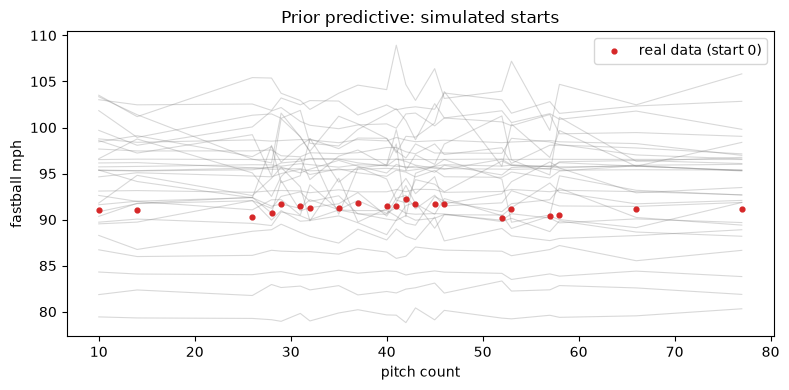

Prior changepoints, 5–95%: [ 20. 147.]


In [8]:
prior = Predictive(fatigue_model, num_samples=200)(jax.random.PRNGKey(SEED), **DATA)
s_id = 0
m = DATA["start_idx"] == s_id
pc_s = DATA["pc"][m]
fig, ax = plt.subplots(figsize=(8, 4))
for k in range(30):
    ax.plot(pc_s, np.asarray(prior["v"][k][m]), color="gray", alpha=0.3, lw=0.8)
ax.scatter(pc_s, V[m], color="tab:red", s=12, zorder=3, label="real data (start 0)")
ax.set_xlabel("pitch count"); ax.set_ylabel("fastball mph"); ax.set_title("Prior predictive: simulated starts")
ax.legend(); plt.tight_layout(); plt.show()
print("Prior changepoints, 5–95%:", np.percentile(np.asarray(prior["tau_start"]), [5, 95]).round(0))

## 5. Fit with NUTS

`init_to_median` starts the sampler at prior medians, which avoids absurd starting changepoints. With the 40-pitcher subset, expect roughly 5–20 minutes on a laptop. Check that **r_hat ≈ 1.00** (< 1.01) and **n_eff** is in the hundreds for the parameters below; if not, raise `num_warmup` / `num_samples`.

In [9]:
kernel = NUTS(fatigue_model, init_strategy=init_to_median, target_accept_prob=0.9)
mcmc = MCMC(kernel, num_warmup=750, num_samples=750, num_chains=2, progress_bar=True)
t0 = time.time()
mcmc.run(jax.random.PRNGKey(SEED), **DATA, v=V)
print(f"Sampling took {(time.time() - t0) / 60:.1f} min")

HYPER = ["mu_tau", "sd_tau_pitcher", "sd_tau_start", "beta", "mu_logslope", "sd_logslope",
         "sd_base_start", "sigma"]
grouped = mcmc.get_samples(group_by_chain=True)
numpyro.diagnostics.print_summary({k: grouped[k] for k in HYPER}, prob=0.9)
post = {k: np.asarray(v) for k, v in mcmc.get_samples().items()}

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

Sampling took 0.0 min

                      mean       std    median      5.0%     95.0%     n_eff     r_hat
          mu_tau     63.86      7.30     63.81     52.31     76.27    288.24      1.00
  sd_tau_pitcher     47.62      5.35     47.22     39.58     56.38    516.87      1.00
    sd_tau_start     38.98      1.55     39.03     36.32     41.41    533.28      1.00
         beta[0]      6.09      1.41      6.09      3.71      8.29    671.25      1.00
         beta[1]     -5.36      1.37     -5.38     -7.68     -3.22    662.80      1.00
         beta[2]      0.60      0.84      0.61     -0.77      1.99    745.06      1.00
         beta[3]      8.94      2.70      8.93      4.57     13.43    700.77      1.00
     mu_logslope     -3.79      0.08     -3.79     -3.92     -3.67    377.99      1.01
     sd_logslope      0.43      0.06      0.42      0.34      0.52    539.32      1.00
   sd_base_start      0.69      0.01      0.69      0.67      0.72    393.55      1.00
           sigma    

## 6. Results

### Covariate effects on the fatigue point

A **negative** temperature β means the decline starts **earlier** (fewer pitches) on hotter days. `P(β < 0)` is the posterior probability of that direction.

**P(β < 0)**.  
< 0.01 or > 0.99:  very strong evidence for the direction (temp_10F, extra_rest, day_game).    
0.05–0.2 or 0.8–0.95: moderate, worth noting.  
0.2–0.8: inconclusive (month: 0.24 → 76% chance it's positive, can't tell).  

,covariate,mean (pitches),5%,95%,P(β < 0)
0,temp_10F,5.64,3.37,8.01,0.0
1,extra_rest,-5.70,-8.30,-3.02,1.0
2,day_game,6.85,2.35,11.70,0.0


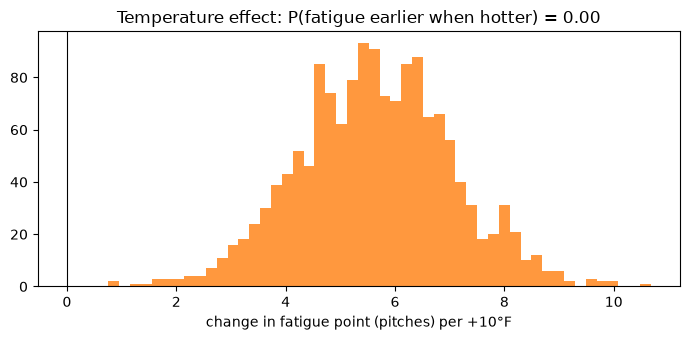

League changepoint (70°F night, normal rest, June): 83 pitches (90%: 72–94)
Typical decline after it: 0.70 mph per 30 pitches


In [41]:
b = post["beta"]
eff = pd.DataFrame({"covariate": COVS, "mean (pitches)": b.mean(0),
                    "5%": np.percentile(b, 5, axis=0), "95%": np.percentile(b, 95, axis=0),
                    "P(β < 0)": (b < 0).mean(0)})
display(eff.round(2))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(b[:, 0], bins=50, color="tab:orange", alpha=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("change in fatigue point (pitches) per +10°F")
ax.set_title(f"Temperature effect: P(fatigue earlier when hotter) = {(b[:, 0] < 0).mean():.2f}")
plt.tight_layout(); plt.show()
print(f"League changepoint (70°F night, normal rest, June): {post['mu_tau'].mean():.0f} pitches "
      f"(90%: {np.percentile(post['mu_tau'], 5):.0f}–{np.percentile(post['mu_tau'], 95):.0f})")
print(f"Typical decline after it: {np.exp(post['mu_logslope']).mean() * 30:.2f} mph per 30 pitches")

### Pitcher fatigue profiles

Gathering player lookup table. This may take a moment.


,pitcher,starts,changepoint,cp 5%,cp 95%,mph lost per 30 pitches after
38,Will Warren,55,-37.000000,-75.5,-3.4,0.5
7,Bailey Ober,46,-35.400002,-67.4,-9.1,0.6
36,Landen Roupp,45,-25.700001,-67.0,4.1,0.6
28,George Kirby,44,-19.299999,-62.7,17.5,0.4
19,Nick Lodolo,45,-16.200001,-67.1,25.5,0.3
17,Jake Irvin,44,-4.200000,-26.5,15.8,0.7
1,Zack Wheeler,45,13.800000,-14.4,37.9,0.4
31,Tanner Bibee,53,25.600000,6.1,43.2,0.6
4,Jeffrey Springs,50,26.799999,12.6,41.5,0.7
2,Matt Boyd,52,26.900000,10.9,41.8,0.6


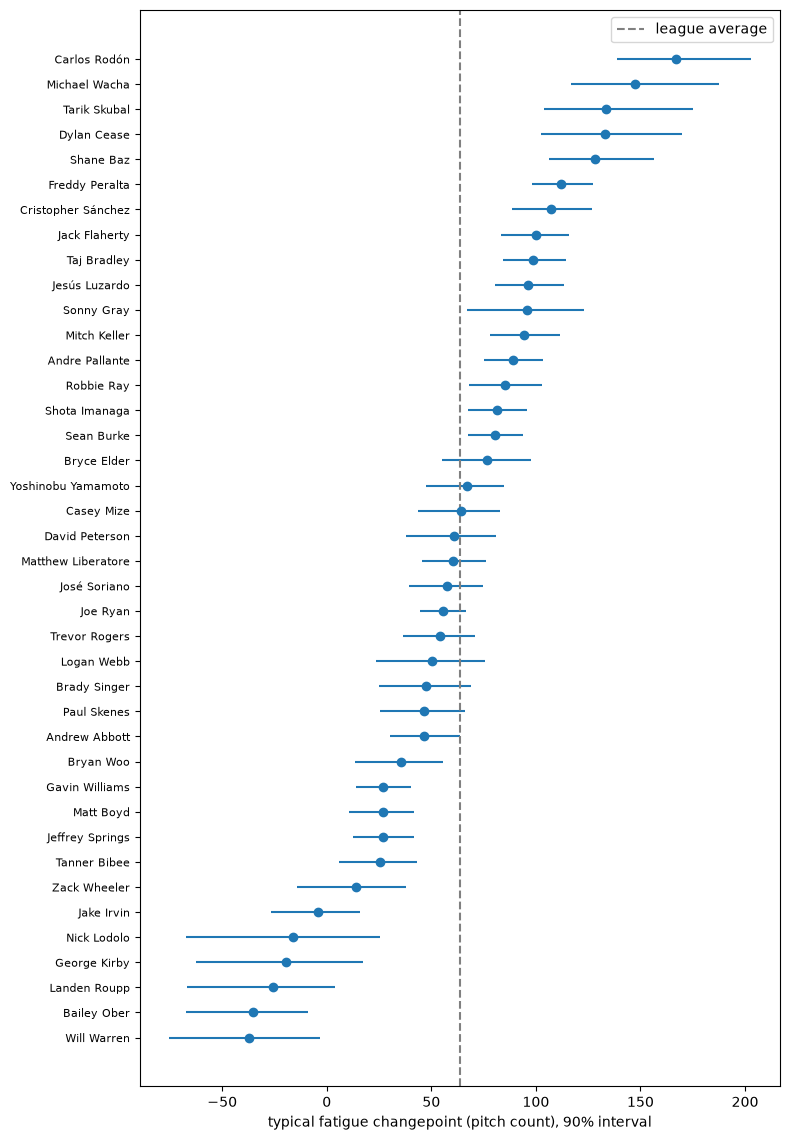

In [11]:
try:
    from pybaseball import playerid_reverse_lookup
    lk = playerid_reverse_lookup([int(p) for p in PITCHERS], key_type="mlbam")
    NAMES = dict(zip(lk["key_mlbam"], (lk["name_first"] + " " + lk["name_last"]).str.title()))
except Exception as e:
    print("Name lookup failed, using IDs:", e)
    NAMES = {}

tp, sp = post["tau_pitcher"], post["slope_pitcher"]
prof = pd.DataFrame({
    "pitcher": [NAMES.get(int(p), str(p)) for p in PITCHERS],
    "starts": S.groupby("pitcher_id").size().reindex(range(len(PITCHERS))).to_numpy(),
    "changepoint": tp.mean(0), "cp 5%": np.percentile(tp, 5, axis=0), "cp 95%": np.percentile(tp, 95, axis=0),
    "mph lost per 30 pitches after": sp.mean(0) * 30,
}).sort_values("changepoint")
prof.to_csv(OUT_DIR / "bayes_pitcher_fatigue.csv", index=False)
display(prof.round(1))

fig, ax = plt.subplots(figsize=(8, 0.25 * len(prof) + 1.5))
yy = np.arange(len(prof))
ax.hlines(yy, prof["cp 5%"], prof["cp 95%"], color="tab:blue")
ax.scatter(prof["changepoint"], yy, color="tab:blue", zorder=3)
ax.set_yticks(yy, prof["pitcher"], fontsize=8)
ax.axvline(post["mu_tau"].mean(), ls="--", color="gray", label="league average")
ax.set_xlabel("typical fatigue changepoint (pitch count), 90% interval"); ax.legend()
plt.tight_layout(); plt.show()

In [17]:
prof.shape

(40, 6)

In [18]:
name_of = {i: NAMES.get(int(p), str(p)) for i, p in enumerate(PITCHERS)}
NEG = prof.loc[prof["changepoint"] < 0, "pitcher"].tolist()           # e.g. Warren, Ober, Roupp, Kirby, Lodolo, Irvin
NORMAL = prof.loc[prof["changepoint"] > 40, "pitcher"].tolist()       # comparison group
print("Negative changepoint:", NEG)

obs["name"] = obs["pitcher_id"].map(name_of)
S["name"] = S["pitcher_id"].map(name_of)
obs["group"] = np.select([obs["name"].isin(NEG), obs["name"].isin(NORMAL)],
                         ["negative changepoint", "changepoint > 40"], "middle")

# Velocity relative to each start's own pitches-10-40 median (removes pitcher-to-pitcher differences)
base = obs[obs["pitch_count"].between(10, 40)].groupby("start_id")["release_speed"].median()
obs["rel_velo"] = obs["release_speed"] - obs["start_id"].map(base)
obs["pc_bin"] = (obs["pitch_count"] // 10) * 10 + 5

Negative changepoint: ['Will Warren', 'Bailey Ober', 'Landen Roupp', 'George Kirby', 'Nick Lodolo', 'Jake Irvin']


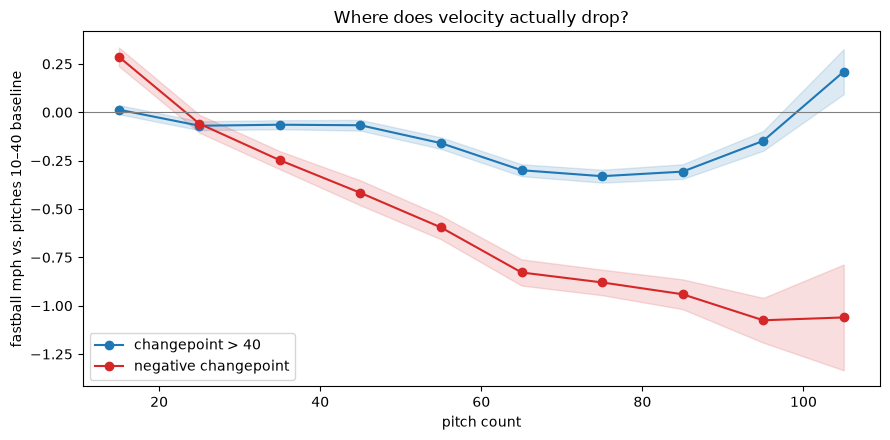

In [19]:
curve = (obs[obs["group"] != "middle"]
           .groupby(["group", "pc_bin"])["rel_velo"].agg(["mean", "sem", "size"]).reset_index())
curve = curve[curve["size"] >= 30]

fig, ax = plt.subplots(figsize=(9, 4.5))
for (g, d), col in zip(curve.groupby("group"), ["tab:blue", "tab:red"]):
    ax.plot(d["pc_bin"], d["mean"], "o-", color=col, label=g)
    ax.fill_between(d["pc_bin"], d["mean"] - 1.96 * d["sem"], d["mean"] + 1.96 * d["sem"], color=col, alpha=0.15)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("pitch count"); ax.set_ylabel("fastball mph vs. pitches 10–40 baseline")
ax.set_title("Where does velocity actually drop?"); ax.legend(); plt.tight_layout(); plt.show()

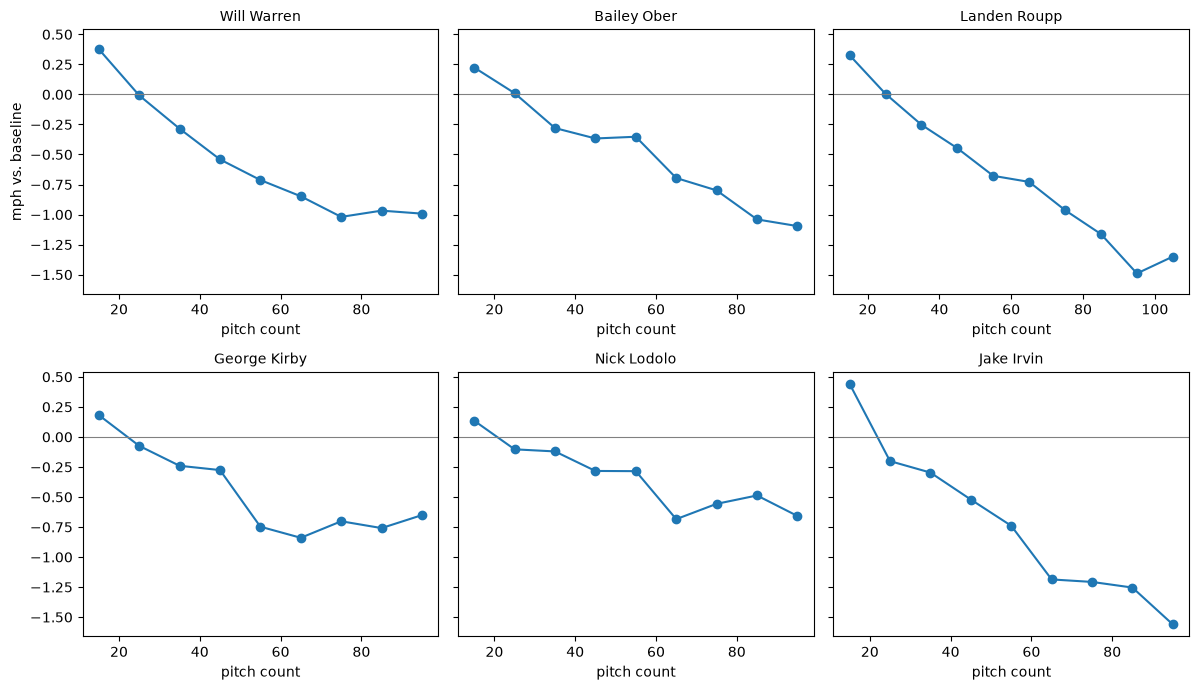

In [20]:
fig, axes = plt.subplots(2, int(np.ceil(len(NEG) / 2)), figsize=(4 * int(np.ceil(len(NEG) / 2)), 7),
                         sharey=True, squeeze=False)
for ax, nm in zip(axes.flat, NEG):
    d = obs[obs["name"] == nm].groupby("pc_bin")["rel_velo"].agg(["mean", "size"])
    d = d[d["size"] >= 15]
    ax.plot(d.index, d["mean"], "o-")
    ax.axhline(0, color="gray", lw=0.8); ax.set_title(nm, fontsize=10); ax.set_xlabel("pitch count")
axes[0, 0].set_ylabel("mph vs. baseline")
plt.tight_layout(); plt.show()

In [21]:
def profile(nm):
    o, s = obs[obs["name"] == nm], S[S["name"] == nm]
    early = o.loc[o["pitch_count"] <= 60]
    drift = np.polyfit(early["pitch_count"], early["rel_velo"], 1)[0] * 30      # mph per 30 pitches, pitches 10-60
    return {
        "pitcher": nm,
        "group": "negative" if nm in NEG else ("normal" if nm in NORMAL else "middle"),
        "starts": len(s),
        "median pitches": s["total_pitches"].median(),
        "% starts ≥ 90": (s["total_pitches"] >= 90).mean() * 100,
        "early drift (mph/30)": drift,
        "pitches 10–20 vs 21–40": (o.loc[o["pitch_count"].between(10, 20), "rel_velo"].mean()
                                   - o.loc[o["pitch_count"].between(21, 40), "rel_velo"].mean()),
        "% sinker": (o["fb_type"] == "SI").mean() * 100,
        "% night": (s["day_night"] == "night").mean() * 100,
        "mean temp": s["temp_f"].mean(),
        "% cool nights (<65°F)": ((s["day_night"] == "night") & (s["temp_f"] < 65)).mean() * 100,
    }

diag = pd.DataFrame([profile(nm) for nm in NEG + NORMAL])
display(diag.round(1))
display(diag.groupby("group").mean(numeric_only=True).round(2))

,pitcher,group,starts,median pitches,% starts ≥ 90,early drift (mph/30),pitches 10–20 vs 21–40,% sinker,% night,mean temp,% cool nights (<65°F)
0,Will Warren,negative,55,88.0,41.8,-0.8,0.5,7.4,65.5,74.2,9.1
1,Bailey Ober,negative,46,88.0,37.0,-0.5,0.4,0.0,47.8,70.1,8.7
2,Landen Roupp,negative,45,92.0,64.4,-0.7,0.5,100.0,64.4,68.5,22.2
3,George Kirby,negative,44,93.5,70.5,-0.6,0.4,39.9,70.5,71.7,11.4
4,Nick Lodolo,negative,45,92.0,66.7,-0.3,0.3,33.1,60.0,77.0,11.1
5,Jake Irvin,negative,44,91.0,54.5,-0.8,0.6,25.6,50.0,73.8,6.8
6,Andrew Abbott,normal,57,95.0,70.2,-0.4,0.1,0.0,54.4,77.1,7.0
7,Paul Skenes,normal,58,95.0,67.2,-0.2,0.1,0.9,60.3,74.8,8.6
8,Brady Singer,normal,58,94.0,69.0,-0.2,0.2,100.0,60.3,75.4,8.6
9,Logan Webb,normal,52,97.5,78.8,-0.4,0.2,97.4,61.5,66.8,28.8


,starts,median pitches,% starts ≥ 90,early drift (mph/30),pitches 10–20 vs 21–40,% sinker,% night,mean temp,% cool nights (<65°F)
group,,,,,,,,,
negative,46.50,90.75,55.81,-0.62,0.43,34.33,59.70,72.55,11.55
normal,50.86,92.88,64.70,-0.12,0.08,23.29,63.19,73.84,11.33


In [ ]:
#% starts ≥ 90" 投满 90 球以上的先发场次比例: 模型看到的几乎都是比赛前段的数据,很少看到比赛后段
#pitches 10–20 vs 21–40: (第 10–20 球的平均相对球速)−(第 21–40 球的平均相对球速)
#明显为正(例如 +0.5 mph):前 10–20 球比后面快,球速是"开头偏高、之后回到正常",不是疲劳。
#接近 0:开头没有特别快,如果还是整场下降,那就是真正的缓慢漂移。

## update the probablistic model
τ 就是疲劳开始的位置。这种模型在统计上叫断棍模型(broken-stick)或曲棍球棒模型(hockey-stick),是变点分析中最经典、最简单的形式。
它符合棒球里常见的直觉。 大家常说投手会"撞墙"(hit a wall):前面状态稳定,某个时间点之后明显下滑。
参数越少,越容易估计。 每场先发都有自己的 τ,如果再加更多形状参数,模型更难分辨哪个参数负责什么,抽样也更慢、更不稳定。

建模 → 检查 → 改进"的循环,正是贝叶斯建模的标准流程。

### Individual starts: data, fitted curve, and where the changepoint likely is

The shaded band is the 90% interval of the fitted velocity curve; the orange histogram along the bottom is the posterior of that start's changepoint. Starts that ended early show a changepoint posterior stretching past the last pitch: the model knows fatigue hadn't clearly started yet.

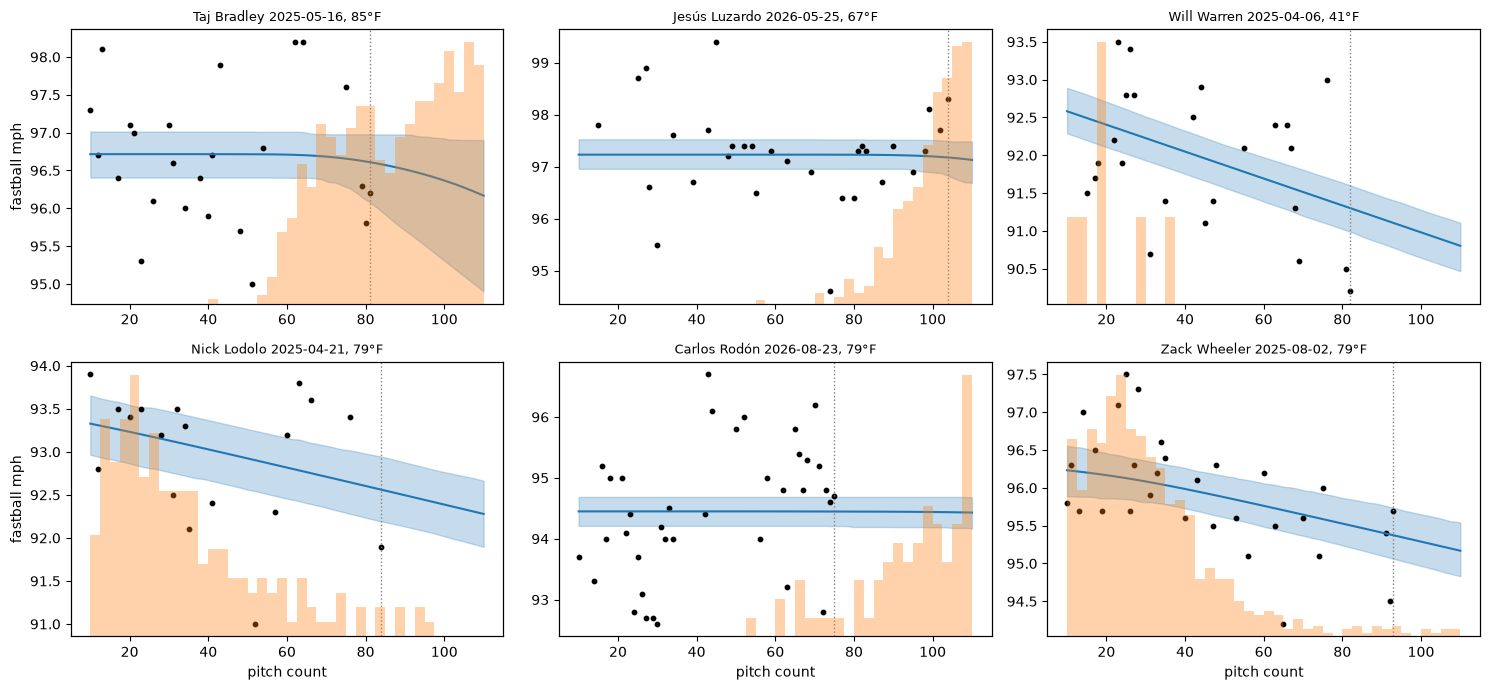

In [12]:
def plot_start(ax, s_id, n_draws=400):
    m = DATA["start_idx"] == s_id
    pc_s, v_s = DATA["pc"][m], V[m]
    j = DATA["pitcher_of_start"][s_id]
    grid = np.linspace(BASE_LO, max(pc_s.max(), 110), 120)
    idx = np.random.default_rng(SEED).choice(len(post["sigma"]), n_draws, replace=False)
    tau = post["tau_start"][idx, s_id][:, None]
    curves = post["base_start"][idx, s_id][:, None] - post["slope_pitcher"][idx, j][:, None] * \
             (SMOOTH * np.logaddexp(0, (grid[None, :] - tau) / SMOOTH))
    ax.fill_between(grid, *np.percentile(curves, [5, 95], axis=0), alpha=0.25, color="tab:blue")
    ax.plot(grid, curves.mean(0), color="tab:blue")
    ax.scatter(pc_s, v_s, s=10, color="black")
    ax2 = ax.twinx(); ax2.hist(post["tau_start"][:, s_id], bins=40, range=(grid[0], grid[-1]),
                               color="tab:orange", alpha=0.35); ax2.set_yticks([])
    ax.axvline(pc_s.max(), color="gray", ls=":", lw=1)
    r = S.loc[s_id]
    ax.set_title(f"{NAMES.get(int(r['pitcher']), r['pitcher'])} {r['game_date']:%Y-%m-%d}, {r['temp_f']:.0f}°F",
                 fontsize=9)

rng = np.random.default_rng(1)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, s_id in zip(axes.flat, rng.choice(len(S), 6, replace=False)):
    plot_start(ax, s_id)
for ax in axes[-1]: ax.set_xlabel("pitch count")
for ax in axes[:, 0]: ax.set_ylabel("fastball mph")
plt.tight_layout(); plt.show()

### Probability fatigue has begun, by pitch count: hot vs. cool day

For a **new** start by a given pitcher, draw a changepoint from the posterior (his typical τ + covariate effects + start-to-start variation) and compute P(τ < pitch count). This is the manager-facing curve.

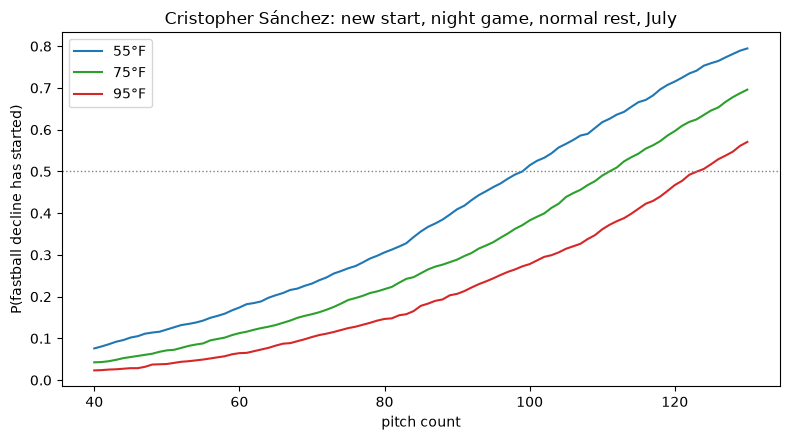

In [13]:
def p_fatigued(j, temp_f, rest=5, month=7, day=0, grid=np.arange(40, 131)):
    x = np.array([(temp_f - 70) / 10, np.clip(rest - 5, -1, 3), month - 6, day], dtype=float)
    noise = np.random.default_rng(SEED).standard_normal(len(post["sigma"]))
    tau_new = post["tau_pitcher"][:, j] + post["beta"] @ x + post["sd_tau_start"] * noise
    return grid, (tau_new[:, None] < grid[None, :]).mean(0)

j = int(np.argmax(S.groupby("pitcher_id").size().to_numpy()))      # pitcher with the most starts
fig, ax = plt.subplots(figsize=(8, 4.5))
for t, col in [(55, "tab:blue"), (75, "tab:green"), (95, "tab:red")]:
    g, p = p_fatigued(j, t)
    ax.plot(g, p, color=col, label=f"{t}°F")
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("pitch count"); ax.set_ylabel("P(fastball decline has started)")
ax.set_title(f"{NAMES.get(int(PITCHERS[j]), PITCHERS[j])}: new start, night game, normal rest, July")
ax.legend(); plt.tight_layout(); plt.show()

### Posterior predictive check

Simulate whole starts from the fitted model and compare them with the real data. If the real points look like a typical simulated start, the model captures the main pattern; systematic misses (e.g. real velocity *rising* early) point to things to add.

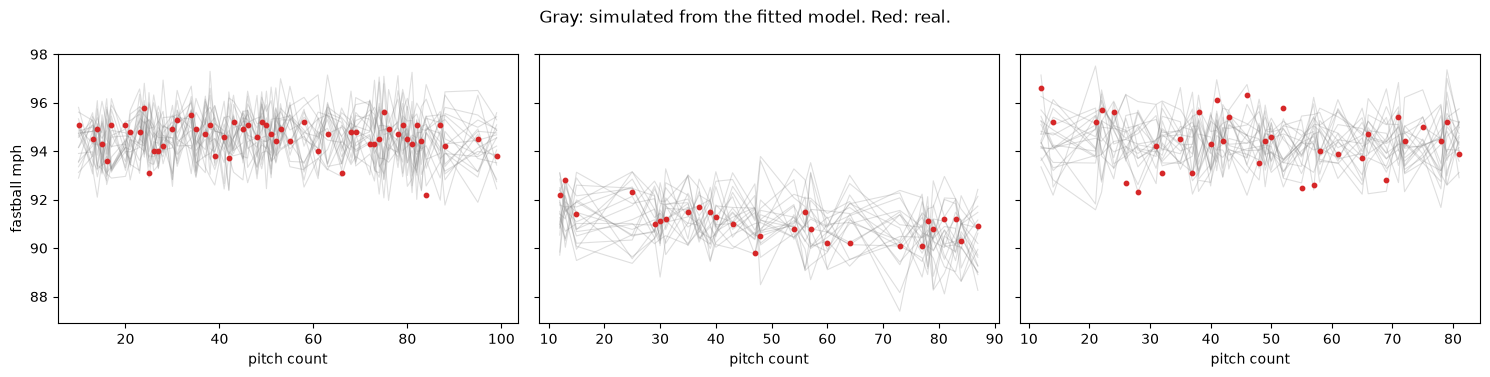

Residual SD: 0.89 mph | posterior sigma: 0.91 mph


In [13]:
DETS = {"tau_pitcher", "slope_pitcher", "tau_start", "base_start"}
sub = {k: v[:200] for k, v in post.items() if k not in DETS}      # 200 draws is plenty for a visual check
ppc = Predictive(fatigue_model, posterior_samples=sub, return_sites=["v"])(
    jax.random.PRNGKey(SEED + 2), **DATA)["v"]
ppc = np.asarray(ppc)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, s_id in zip(axes, np.random.default_rng(3).choice(len(S), 3, replace=False)):
    m = DATA["start_idx"] == s_id
    for k in range(20):
        ax.plot(DATA["pc"][m], ppc[k][m], color="gray", alpha=0.25, lw=0.8)
    ax.scatter(DATA["pc"][m], V[m], color="tab:red", s=10, zorder=3)
    ax.set_xlabel("pitch count")
axes[0].set_ylabel("fastball mph")
plt.suptitle("Gray: simulated from the fitted model. Red: real."); plt.tight_layout(); plt.show()

resid = V - ppc.mean(0)
print(f"Residual SD: {resid.std():.2f} mph | posterior sigma: {post['sigma'].mean():.2f} mph")

## 7. Compare with the threshold rule

For starts where the old rule (8-fastball average ≥ 1 mph below the pitch 10–40 baseline) fired, compare that pitch count with the posterior median changepoint. They measure slightly different things (the rule fires *after* a 1-mph drop has accumulated; τ is where the decline *begins*), so expect the rule's value to be later.

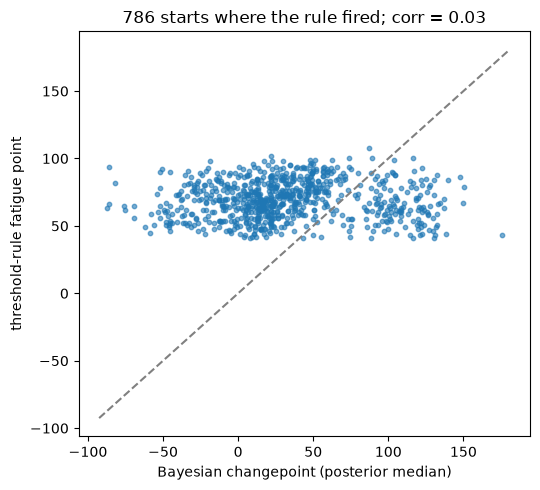

In [15]:
def rule_point(g, drop=1.0, window=8, base_hi=40):
    g = g.sort_values("pitch_count")
    base = g.loc[g["pitch_count"] <= base_hi, "release_speed"].median()
    roll = g["release_speed"].rolling(window).mean()
    hit = g[(g["pitch_count"] > base_hi) & (roll <= base - drop)]
    return hit["pitch_count"].iloc[0] if len(hit) else np.nan

rule = obs.groupby("start_id").apply(rule_point, include_groups=False)
cmp_ = pd.DataFrame({"rule": rule, "tau_median": np.median(post["tau_start"], axis=0)[rule.index]}).dropna()
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(cmp_["tau_median"], cmp_["rule"], s=10, alpha=0.6)
lim = [cmp_.min().min() - 5, cmp_.max().max() + 5]
ax.plot(lim, lim, ls="--", color="gray")
ax.set_xlabel("Bayesian changepoint (posterior median)"); ax.set_ylabel("threshold-rule fatigue point")
ax.set_title(f"{len(cmp_)} starts where the rule fired; corr = {cmp_.corr().iloc[0, 1]:.2f}")
plt.tight_layout(); plt.show()

## Next steps
- **Scale up:** `N_PITCHERS = None`. If NUTS gets too slow, fit with SVI (`AutoNormal`) first, then confirm key results with NUTS on a subset.
- **More signals:** model spin rate and release height jointly with velocity, sharing the changepoint.
- **Better weather:** hourly temperature and dew point (heat index) at each ballpark instead of first-pitch temperature.
- **Retractable-roof parks:** compare open vs. closed games in the same stadium, a cleaner natural experiment.
- **Compare with the Cox model:** do both point the same way on temperature?

## upgrade the model

In [7]:
N_PITCHERS

40

In [8]:
if N_PITCHERS:
    keep = starts["pitcher"].value_counts().head(N_PITCHERS).index
    S = starts[starts["pitcher"].isin(keep)].reset_index(drop=True)
else:
    S = starts.reset_index(drop=True)

S["temp_10F"] = (S["temp_f"] - 70) / 10
S["extra_rest"] = (S["rest_days"].fillna(5) - 5).clip(-1, 3)
S["day_game"] = (S["day_night"] == "day").astype(float)
COVS = ["temp_10F", "extra_rest", "day_game"]          # month removed

S["start_id"] = np.arange(len(S))
S["pitcher_id"], PITCHERS = pd.factorize(S["pitcher"])
obs = fb.merge(S[["game_pk", "pitcher", "start_id", "pitcher_id"]], on=["game_pk", "pitcher"])

PC_CENTER = 40.0       # drift is measured around pitch 40, so base_start = velocity near pitch 40

DATA = dict(
    pc=obs["pitch_count"].to_numpy(np.float32),
    start_idx=obs["start_id"].to_numpy(),
    pitcher_of_start=S["pitcher_id"].to_numpy(),
    X=S[COVS].to_numpy(np.float32),
    n_starts=len(S), n_pitchers=len(PITCHERS),
    v_mean=float(obs["release_speed"].mean()),
)
V = obs["release_speed"].to_numpy(np.float32)
print(f"{len(S):,} starts | {len(PITCHERS)} pitchers | {len(obs):,} fastballs")
display(S[COVS].describe().round(2))

2,008 starts | 40 pitchers | 62,621 fastballs


,temp_10F,extra_rest,day_game
count,2008.00,2008.00,2008.00
mean,0.36,0.98,0.37
std,1.13,0.93,0.48
min,-3.70,0.00,0.00
25%,-0.30,0.00,0.00
50%,0.50,1.00,0.00
75%,1.20,1.00,1.00
max,3.10,3.00,1.00


In [9]:
import jax
import jax.numpy as jnp
import numpyro
import numpyro.diagnostics
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, Predictive, init_to_median

def hinge(x):
    return SMOOTH * jax.nn.softplus(x / SMOOTH)

def fatigue_model(pc, start_idx, pitcher_of_start, X, n_starts, n_pitchers, v_mean, v=None):
    # ---- League level ----
    mu_tau = numpyro.sample("mu_tau", dist.Normal(85.0, 20.0))
    sd_tau_pitcher = numpyro.sample("sd_tau_pitcher", dist.HalfNormal(15.0))
    sd_tau_start = numpyro.sample("sd_tau_start", dist.HalfNormal(15.0))
    beta = numpyro.sample("beta", dist.Normal(0.0, 10.0).expand([X.shape[1]]).to_event(1))
    mu_logslope = numpyro.sample("mu_logslope", dist.Normal(jnp.log(0.03), 0.7))
    sd_logslope = numpyro.sample("sd_logslope", dist.HalfNormal(0.5))
    # NEW: gradual drift over the whole start (mph per pitch). Narrow prior centered on 0:
    # ±0.01 mph/pitch = ±0.3 mph per 30 pitches, so drift only appears when the data support it.
    mu_drift = numpyro.sample("mu_drift", dist.Normal(0.0, 0.01))
    sd_drift = numpyro.sample("sd_drift", dist.HalfNormal(0.01))
    sd_base_start = numpyro.sample("sd_base_start", dist.HalfNormal(1.0))
    sigma = numpyro.sample("sigma", dist.HalfNormal(1.5))

    # ---- Pitcher level ----
    with numpyro.plate("pitchers", n_pitchers):
        tau_p = numpyro.deterministic(
            "tau_pitcher", mu_tau + sd_tau_pitcher * numpyro.sample("z_tau_p", dist.Normal(0.0, 1.0)))
        slope_p = numpyro.deterministic(
            "slope_pitcher", jnp.exp(mu_logslope + sd_logslope * numpyro.sample("z_slope_p", dist.Normal(0.0, 1.0))))
        drift_p = numpyro.deterministic(
            "drift_pitcher", mu_drift + sd_drift * numpyro.sample("z_drift_p", dist.Normal(0.0, 1.0)))
        base_p = numpyro.sample("base_pitcher", dist.Normal(v_mean, 5.0))

    # ---- Start level ----
    with numpyro.plate("starts", n_starts):
        tau_s = numpyro.deterministic(
            "tau_start", tau_p[pitcher_of_start] + X @ beta
            + sd_tau_start * numpyro.sample("z_tau_s", dist.Normal(0.0, 1.0)))
        base_s = numpyro.deterministic(
            "base_start", base_p[pitcher_of_start]
            + sd_base_start * numpyro.sample("z_base_s", dist.Normal(0.0, 1.0)))

    # ---- Pitch level ----
    j = pitcher_of_start[start_idx]
    mu = (base_s[start_idx]
          + drift_p[j] * (pc - PC_CENTER)                      # gradual change all game
          - slope_p[j] * hinge(pc - tau_s[start_idx]))         # extra fatigue drop after the changepoint
    with numpyro.plate("pitches", pc.shape[0]):
        numpyro.sample("v", dist.Normal(mu, sigma), obs=v)

In [ ]:
kernel = NUTS(fatigue_model, init_strategy=init_to_median, target_accept_prob=0.9)
mcmc = MCMC(kernel, num_warmup=1000, num_samples=750, num_chains=2, progress_bar=True)
#1,000 warmup steps, 750 kept draws
#Why run two? As a check. If both walkers, starting differently, end up describing the same distribution, 
#you can trust that it’s the real answer and not one walker stuck in a corner. 
#r_hat measures exactly that agreement: 1.00 means the chains agree.
t0 = time.time()
mcmc.run(jax.random.PRNGKey(SEED), **DATA, v=V)
print(f"Sampling took {(time.time() - t0) / 60:.1f} min")

HYPER = ["mu_tau", "sd_tau_pitcher", "sd_tau_start", "beta", "mu_logslope", "sd_logslope",
         "mu_drift", "sd_drift", "sd_base_start", "sigma"]
grouped = mcmc.get_samples(group_by_chain=True)
numpyro.diagnostics.print_summary({k: grouped[k] for k in HYPER}, prob=0.9)
post = {k: np.asarray(v) for k, v in mcmc.get_samples().items()}
#mcmc.get_samples() returns all kept draws. Both chains are stacked together, so 2 × 750 = 1,500 draws.

#Effective number of independent draws (n_eff)
#n_eff is that “worth”: how many independent draws your correlated draws are equivalent to.

#the mean of mu_tau (82.5) is accurate to about ±7 / √121 ≈ ±0.6 pitches. 
#That’s good enough here. The 5% and 95% tails are less stable, because they need more draws to estimate.

# Rough guide:
# Under 100: don’t trust the intervals; run longer.
# 100–400: fine for exploring.
# Over 400: solid for reporting.
# To raise it, increase num_samples, run more chains, or reparameterize the model so the walker moves more easily.

  0%|          | 0/1750 [00:00<?, ?it/s]

  0%|          | 0/1750 [00:00<?, ?it/s]

Sampling took 0.1 min

                      mean       std    median      5.0%     95.0%     n_eff     r_hat
          mu_tau     82.51      6.97     82.42     71.68     93.89    121.39      1.01
  sd_tau_pitcher     35.11      4.83     34.68     28.19     43.33    207.21      1.00
    sd_tau_start     44.57      1.95     44.43     41.74     48.05    341.62      1.01
         beta[0]      5.64      1.41      5.63      3.40      8.03    356.91      1.00
         beta[1]     -5.70      1.68     -5.76     -8.30     -3.01    369.69      1.00
         beta[2]      6.85      2.83      6.75      2.50     11.80    529.31      1.00
     mu_logslope     -3.76      0.07     -3.76     -3.88     -3.66    248.96      1.00
     sd_logslope      0.33      0.06      0.33      0.22      0.43    194.27      1.01
        mu_drift     -0.00      0.00     -0.00     -0.00      0.00    205.41      1.01
        sd_drift      0.01      0.00      0.01      0.01      0.01    378.05      1.00
   sd_base_start    

,covariate,mean (pitches),5%,95%,P(β < 0)
0,temp_10F,5.64,3.37,8.01,0.0
1,extra_rest,-5.70,-8.30,-3.02,1.0
2,day_game,6.85,2.35,11.70,0.0


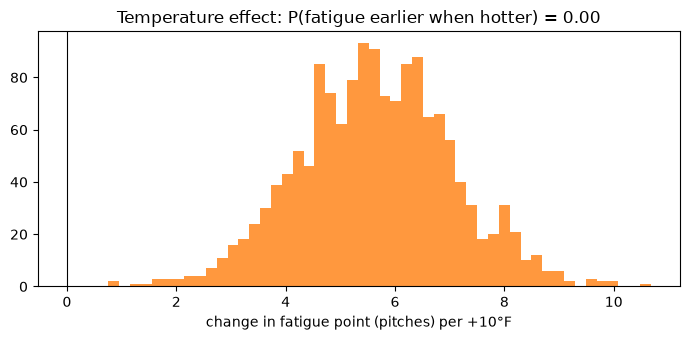

League changepoint (70°F night, normal rest): 83 pitches (90%: 72–94)
League drift before it: -0.02 mph per 30 pitches (90%: -0.09 to +0.05)
Extra decline after the changepoint: 0.70 mph per 30 pitches


In [ ]:
b = post["beta"]
eff = pd.DataFrame({"covariate": COVS, "mean (pitches)": b.mean(0),
                    "5%": np.percentile(b, 5, axis=0), "95%": np.percentile(b, 95, axis=0),
                    "P(β < 0)": (b < 0).mean(0)})
display(eff.round(2))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(b[:, 0], bins=50, color="tab:orange", alpha=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("change in fatigue point (pitches) per +10°F")
ax.set_title(f"Temperature effect: P(fatigue earlier when hotter) = {(b[:, 0] < 0).mean():.2f}")
plt.tight_layout(); plt.show()

print(f"League changepoint (70°F night, normal rest): {post['mu_tau'].mean():.0f} pitches "
      f"(90%: {np.percentile(post['mu_tau'], 5):.0f}–{np.percentile(post['mu_tau'], 95):.0f})")
print(f"League drift before it: {post['mu_drift'].mean() * 30:+.2f} mph per 30 pitches "
      f"(90%: {np.percentile(post['mu_drift'], 5) * 30:+.2f} to {np.percentile(post['mu_drift'], 95) * 30:+.2f})")
#"The 90% interval (−0.09 to +0.05) includes 0, so at the league level there’s no clear drift. Individual pitchers do drift (sd_drift); they just cancel out on average.
print(f"Extra decline after the changepoint: {np.exp(post['mu_logslope']).mean() * 30:.2f} mph per 30 pitches")

In [ ]:
#The typical starter’s fastball holds steady with no real drift until about pitch 83, 
# then fades about 0.7 mph every 30 pitches. 
# A pitcher who goes 113 pitches is about 0.7 mph slower at the end than at the changepoint.

/Users/jinzhixu/spark-env/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(
/Users/jinzhixu/spark-env/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.69 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


Computed from 1500 posterior samples and 62621 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -84442.96   205.61
p_loo     2848.71        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.69]   (good)     62556   99.9%
   (0.69, 1]   (bad)         57    0.1%
   (1, Inf)   (very bad)     8    0.0%


elpd_loo per pitch: -1.348
p_loo (effective parameters): 2849  vs. raw parameter count: 4,188.0
Pareto k > 0.7 (LOO unreliable for that pitch): 57 of 62,621 pitches


,mean_elpd,max_k,n_high_k
pc_bin,,,
15.0,-1.345,1.117,4
25.0,-1.333,1.040,6
35.0,-1.309,0.403,0
45.0,-1.335,0.473,0
55.0,-1.351,0.492,0
65.0,-1.376,0.718,1
75.0,-1.358,1.324,11
85.0,-1.372,1.282,11
95.0,-1.379,1.324,22


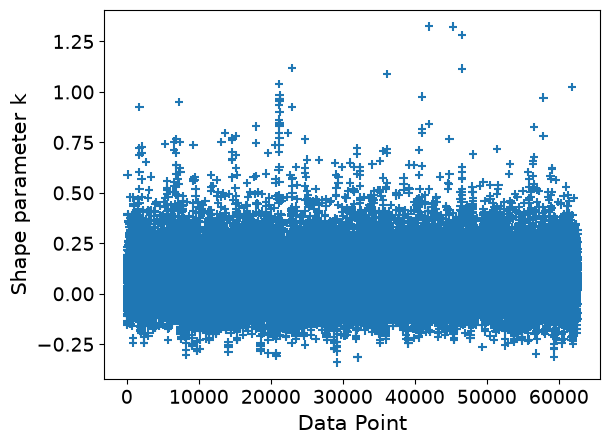

In [ ]:
import arviz as az

idata = az.from_numpyro(mcmc)                 # mcmc = the drift model fit
loo = az.loo(idata, pointwise=True)
print(loo)

n_params = sum(np.prod(v.shape[1:]) for k, v in post.items()
               if k not in {"tau_pitcher", "slope_pitcher", "drift_pitcher", "tau_start", "base_start"})
print(f"\nelpd_loo per pitch: {loo.elpd_loo / len(V):.3f}")
print(f"p_loo (effective parameters): {loo.p_loo:.0f}  vs. raw parameter count: {n_params:,}")

k = np.asarray(loo.pareto_k)
print(f"Pareto k > 0.7 (LOO unreliable for that pitch): {(k > 0.7).sum()} of {len(k):,} pitches")

# Where are the hard-to-predict pitches? Pareto k and pointwise elpd by pitch count
pt = pd.DataFrame({"pc_bin": (DATA["pc"] // 10) * 10 + 5, "elpd_i": np.asarray(loo.loo_i), "k": k})
display(pt.groupby("pc_bin").agg(mean_elpd=("elpd_i", "mean"), max_k=("k", "max"),
                                 n_high_k=("k", lambda x: (x > 0.7).sum())).round(3))
az.plot_khat(loo); plt.show()

,pitcher,starts,drift (mph/30),drift 5%,drift 95%,changepoint,cp 5%,cp 95%,extra mph lost per 30 after cp
7,Bailey Ober,46,0.19,0.02,0.37,-28.100000,-53.139999,-7.760000,0.74
22,Gavin Williams,57,-0.07,-0.17,0.04,32.689999,18.420000,47.750000,0.73
1,Zack Wheeler,45,-0.04,-0.24,0.15,43.490002,-6.820000,129.309998,0.42
3,Robbie Ray,55,0.39,0.31,0.47,48.680000,34.330002,62.450001,0.77
23,Shane Baz,56,0.48,0.32,0.63,53.099998,30.129999,84.540001,0.72
21,José Soriano,52,0.06,-0.08,0.20,53.830002,30.570000,84.800003,0.67
24,Tarik Skubal,53,0.45,0.34,0.55,54.560001,33.470001,73.839996,0.65
25,Trevor Rogers,44,0.02,-0.08,0.13,56.349998,31.700001,78.089996,0.65
10,Dylan Cease,49,0.53,0.45,0.61,58.730000,44.849998,72.309998,0.79
2,Matt Boyd,52,-0.22,-0.33,-0.10,59.880001,32.330002,92.199997,0.53


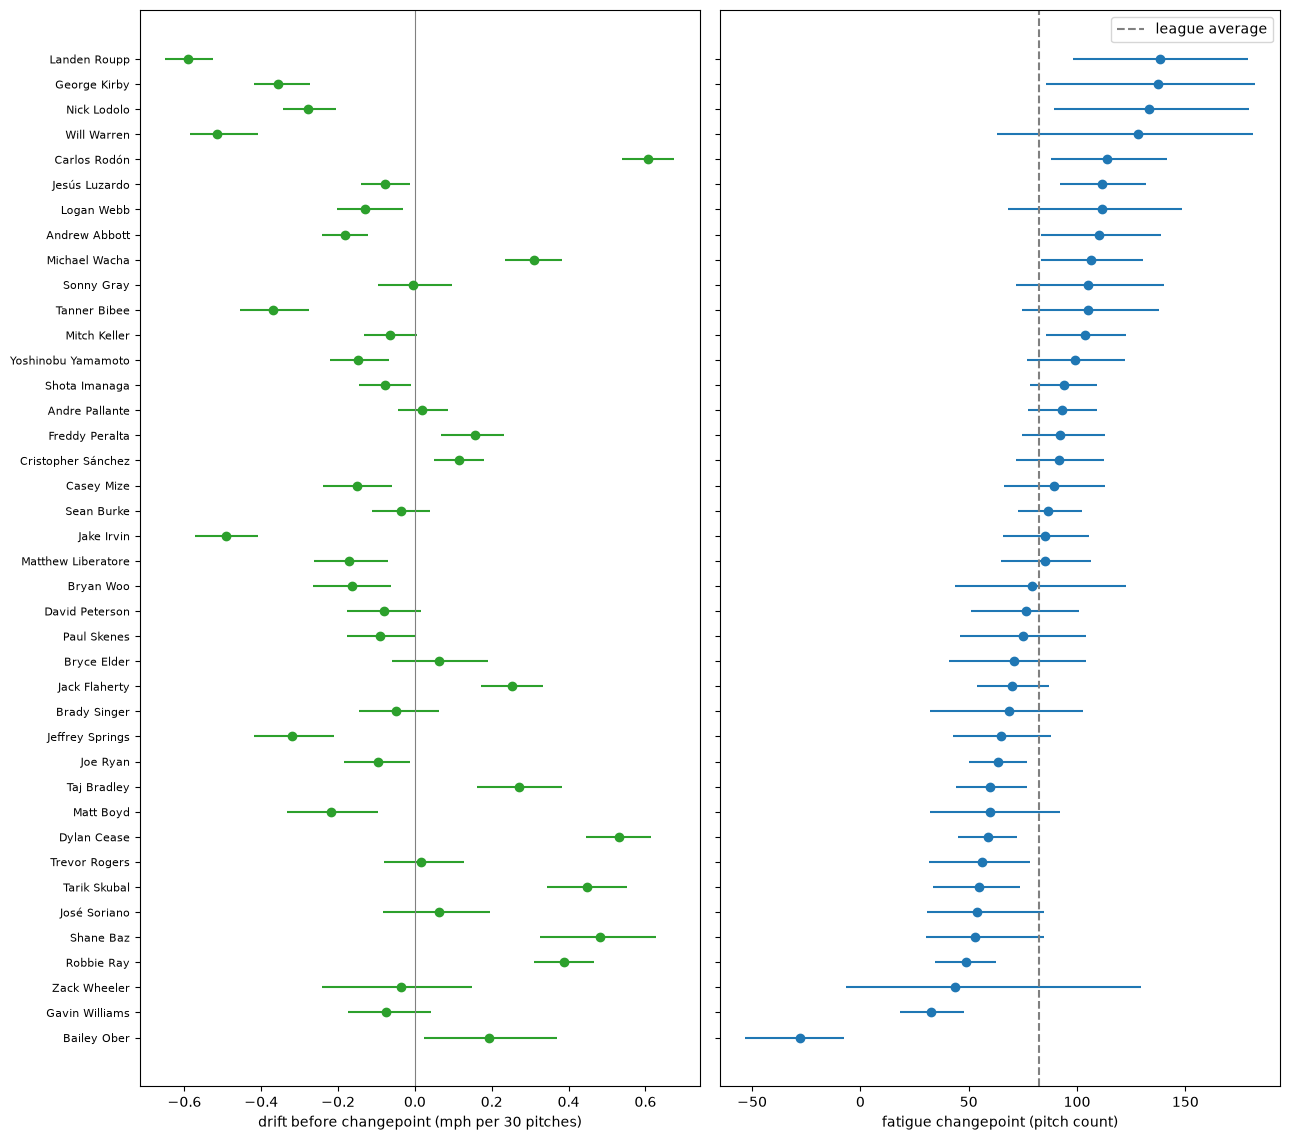

In [ ]:
try:
    from pybaseball import playerid_reverse_lookup
    lk = playerid_reverse_lookup([int(p) for p in PITCHERS], key_type="mlbam")
    NAMES = dict(zip(lk["key_mlbam"], (lk["name_first"] + " " + lk["name_last"]).str.title()))
except Exception as e:
    print("Name lookup failed, using IDs:", e)
    NAMES = {}

tp, sp, dp = post["tau_pitcher"], post["slope_pitcher"], post["drift_pitcher"]
prof = pd.DataFrame({
    "pitcher": [NAMES.get(int(p), str(p)) for p in PITCHERS],
    "starts": S.groupby("pitcher_id").size().reindex(range(len(PITCHERS))).to_numpy(),
    "drift (mph/30)": dp.mean(0) * 30,
    "drift 5%": np.percentile(dp, 5, axis=0) * 30, 
    "drift 95%": np.percentile(dp, 95, axis=0) * 30,
    "changepoint": tp.mean(0), 
    "cp 5%": np.percentile(tp, 5, axis=0),
    "cp 95%": np.percentile(tp, 95, axis=0),
    "extra mph lost per 30 after cp": sp.mean(0) * 30,
}).sort_values("changepoint")
prof.to_csv(OUT_DIR / "bayes_pitcher_fatigue_drift.csv", index=False)
display(prof.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 0.25 * len(prof) + 1.5), sharey=True)
yy = np.arange(len(prof))
axes[0].hlines(yy, prof["drift 5%"], prof["drift 95%"], color="tab:green")
axes[0].scatter(prof["drift (mph/30)"], yy, color="tab:green", zorder=3)
axes[0].axvline(0, color="gray", lw=0.8)
axes[0].set_xlabel("drift before changepoint (mph per 30 pitches)")
axes[0].set_yticks(yy, prof["pitcher"], fontsize=8)
axes[1].hlines(yy, prof["cp 5%"], prof["cp 95%"], color="tab:blue")
axes[1].scatter(prof["changepoint"], yy, color="tab:blue", zorder=3)
axes[1].axvline(post["mu_tau"].mean(), ls="--", color="gray", label="league average")
axes[1].set_xlabel("fatigue changepoint (pitch count)"); axes[1].legend()
plt.tight_layout(); plt.show()

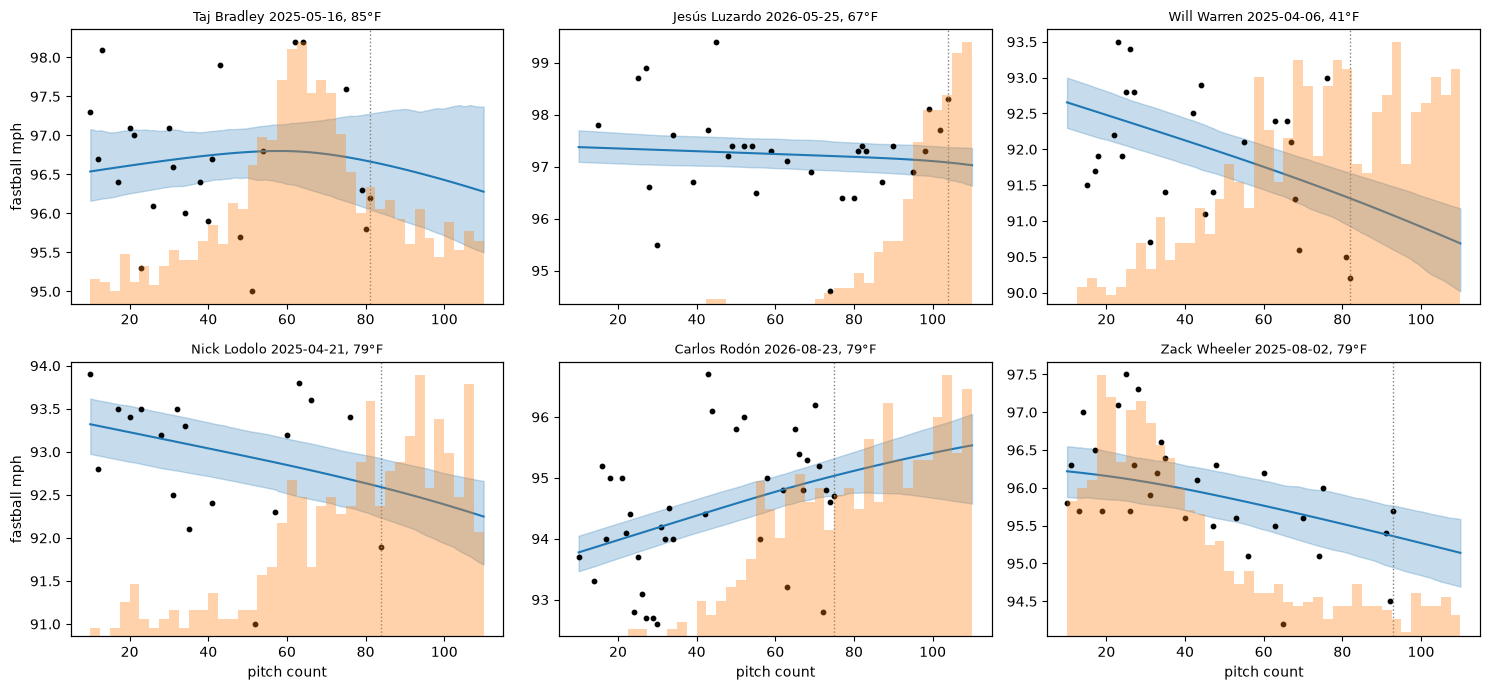

In [28]:
def plot_start(ax, s_id, n_draws=400):
    m = DATA["start_idx"] == s_id
    pc_s, v_s = DATA["pc"][m], V[m]
    j = DATA["pitcher_of_start"][s_id]
    grid = np.linspace(BASE_LO, max(pc_s.max(), 110), 120)
    idx = np.random.default_rng(SEED).choice(len(post["sigma"]), n_draws, replace=False)
    tau = post["tau_start"][idx, s_id][:, None]
    curves = (post["base_start"][idx, s_id][:, None]
              + post["drift_pitcher"][idx, j][:, None] * (grid[None, :] - PC_CENTER)
              - post["slope_pitcher"][idx, j][:, None] * (SMOOTH * np.logaddexp(0, (grid[None, :] - tau) / SMOOTH)))
    ax.fill_between(grid, *np.percentile(curves, [5, 95], axis=0), alpha=0.25, color="tab:blue")
    ax.plot(grid, curves.mean(0), color="tab:blue")
    ax.scatter(pc_s, v_s, s=10, color="black")
    ax2 = ax.twinx(); ax2.hist(post["tau_start"][:, s_id], bins=40, range=(grid[0], grid[-1]),
                               color="tab:orange", alpha=0.35); ax2.set_yticks([])
    ax.axvline(pc_s.max(), color="gray", ls=":", lw=1)
    r = S.loc[s_id]
    ax.set_title(f"{NAMES.get(int(r['pitcher']), r['pitcher'])} {r['game_date']:%Y-%m-%d}, {r['temp_f']:.0f}°F",
                 fontsize=9)

rng = np.random.default_rng(1)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, s_id in zip(axes.flat, rng.choice(len(S), 6, replace=False)):
    plot_start(ax, s_id)
for ax in axes[-1]: ax.set_xlabel("pitch count")
for ax in axes[:, 0]: ax.set_ylabel("fastball mph")
plt.tight_layout(); plt.show()

Bailey Ober: 46 starts


,game_date,total_pitches,temp_f,day_night
344,2025-03-30,77,74.0,day
345,2025-04-05,84,38.0,day
346,2025-04-10,73,67.0,day
347,2025-04-15,77,53.0,night
348,2025-04-22,87,69.0,night
349,2025-04-28,102,71.0,night
350,2025-05-03,94,82.0,day
351,2025-05-08,91,62.0,day
352,2025-05-14,102,66.0,day
353,2025-05-25,89,67.0,day


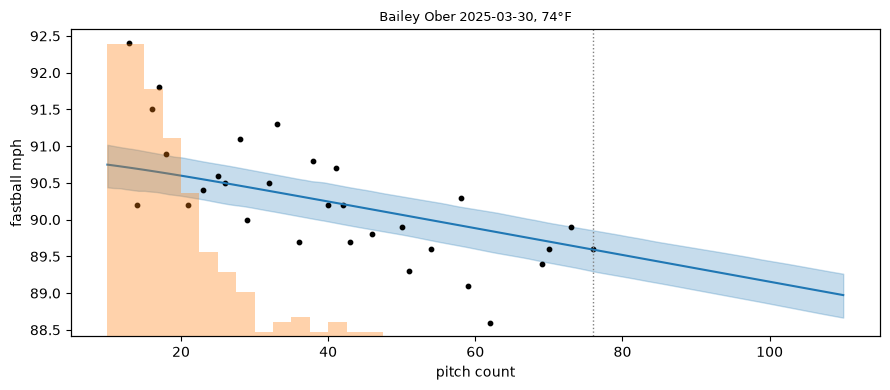

In [38]:
PID = 641927                                   # Bailey Ober (integer, no quotes)
ober = S.index[S["pitcher"] == PID].to_numpy() # his start numbers (s_id values)
print(f"{NAMES.get(PID, PID)}: {len(ober)} starts")
display(S.loc[ober, ["game_date", "total_pitches", "temp_f", "day_night"]])

fig, ax = plt.subplots(figsize=(9, 4))
plot_start(ax, ober[0])                        # his first start in the data
ax.set_xlabel("pitch count"); ax.set_ylabel("fastball mph")
plt.tight_layout(); plt.show()

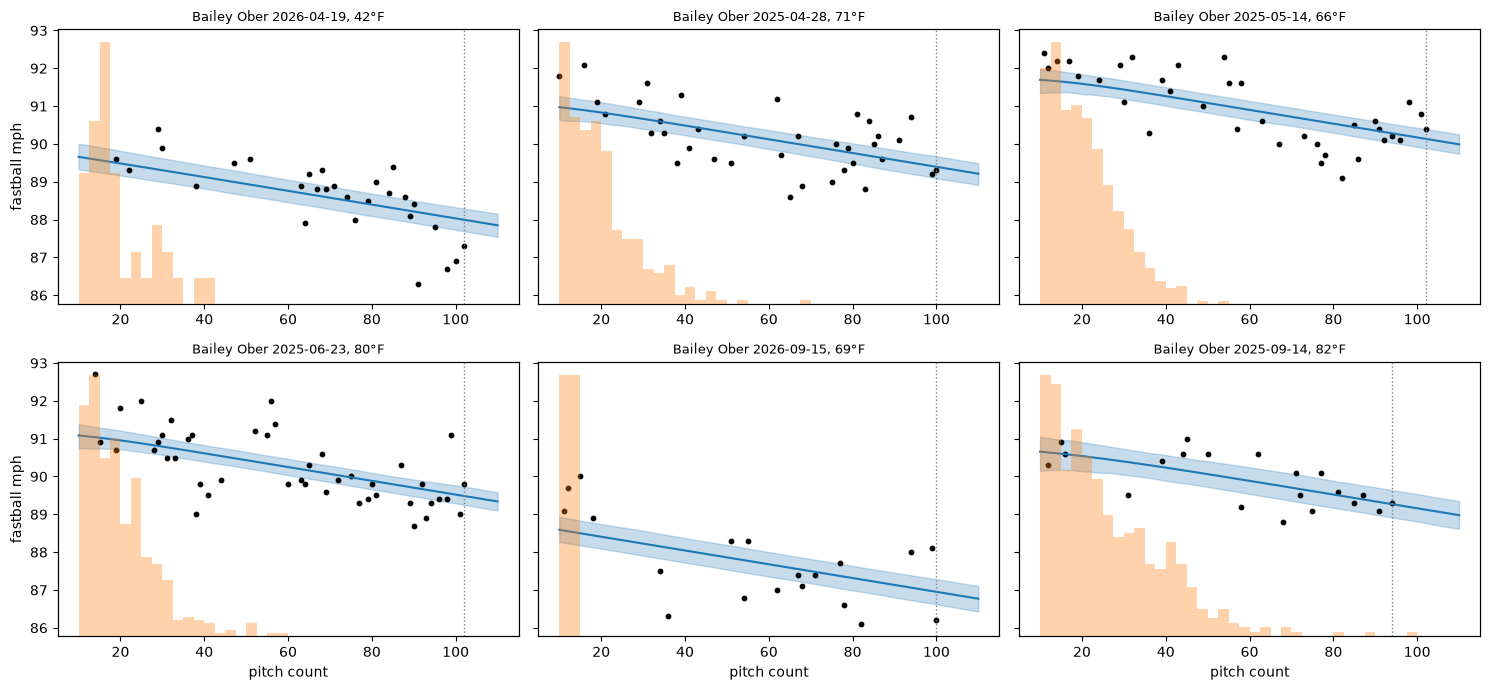

In [39]:
show = S.loc[ober].sort_values("total_pitches", ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, s_id in zip(axes.flat, show):
    plot_start(ax, s_id)
for ax in axes[-1]: ax.set_xlabel("pitch count")
for ax in axes[:, 0]: ax.set_ylabel("fastball mph")
plt.tight_layout(); plt.show()

In [43]:
def pid_by_name(full_name):
    hits = [pid for pid, nm in NAMES.items() if nm.lower() == full_name.lower()]
    if not hits:
        raise ValueError(f"{full_name} not found; check spelling or whether he's in the 40-pitcher subset")
    return int(hits[0])

PIDS = {"Bailey Ober": pid_by_name("Bailey Ober"), "Gavin Williams": pid_by_name("Gavin Williams")}
print(PIDS)

rows = []
for nm, pid in PIDS.items():
    j = int(np.where(PITCHERS == pid)[0][0])
    s = S[S["pitcher"] == pid]
    tp = post["tau_pitcher"][:, j]
    row = {"pitcher": nm, "starts": len(s),
           "median pitches": s["total_pitches"].median(),
           "% starts ≥ 90": (s["total_pitches"] >= 90).mean() * 100,
           "changepoint": tp.mean(), "cp 5%": np.percentile(tp, 5), "cp 95%": np.percentile(tp, 95),
           "extra mph lost /30 after cp": post["slope_pitcher"][:, j].mean() * 30}
    if "drift_pitcher" in post:                                   # only in the drift model
        row["drift mph/30"] = post["drift_pitcher"][:, j].mean() * 30
    rows.append(row)
display(pd.DataFrame(rows).round(1))

{'Bailey Ober': 641927, 'Gavin Williams': 668909}


,pitcher,starts,median pitches,% starts ≥ 90,changepoint,cp 5%,cp 95%,extra mph lost /30 after cp,drift mph/30
0,Bailey Ober,46,88.0,37.0,-28.100000,-53.099998,-7.800000,0.7,0.2
1,Gavin Williams,57,96.0,75.4,32.700001,18.400000,47.700001,0.7,-0.1


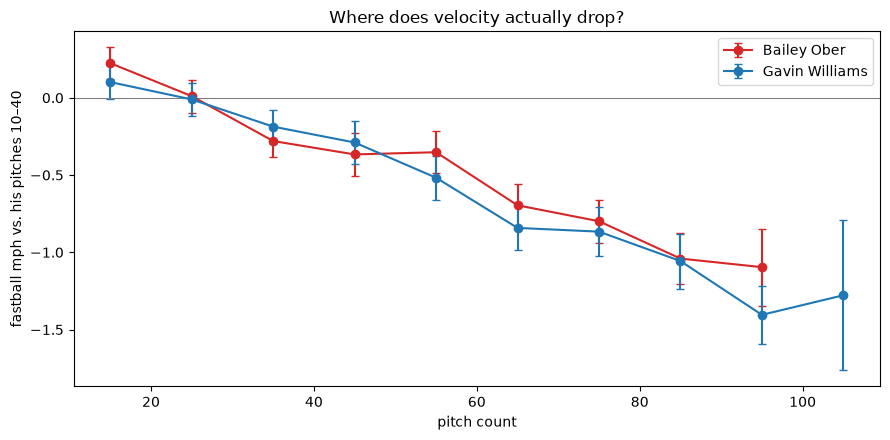

In [45]:
base = obs[obs["pitch_count"].between(10, 40)].groupby("start_id")["release_speed"].median()
obs["rel_velo"] = obs["release_speed"] - obs["start_id"].map(base)
obs["pc_bin"] = (obs["pitch_count"] // 10) * 10 + 5

fig, ax = plt.subplots(figsize=(9, 4.5))
for (nm, pid), col in zip(PIDS.items(), ["tab:red", "tab:blue"]):
    d = (obs[obs["pitcher"] == pid].groupby("pc_bin")["rel_velo"]
           .agg(["mean", "sem", "size"]).query("size >= 15"))
    ax.errorbar(d.index, d["mean"], yerr=1.96 * d["sem"], fmt="o-", capsize=3, color=col, label=nm)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("pitch count"); ax.set_ylabel("fastball mph vs. his pitches 10–40")
ax.set_title("Where does velocity actually drop?"); ax.legend()
plt.tight_layout(); plt.show()

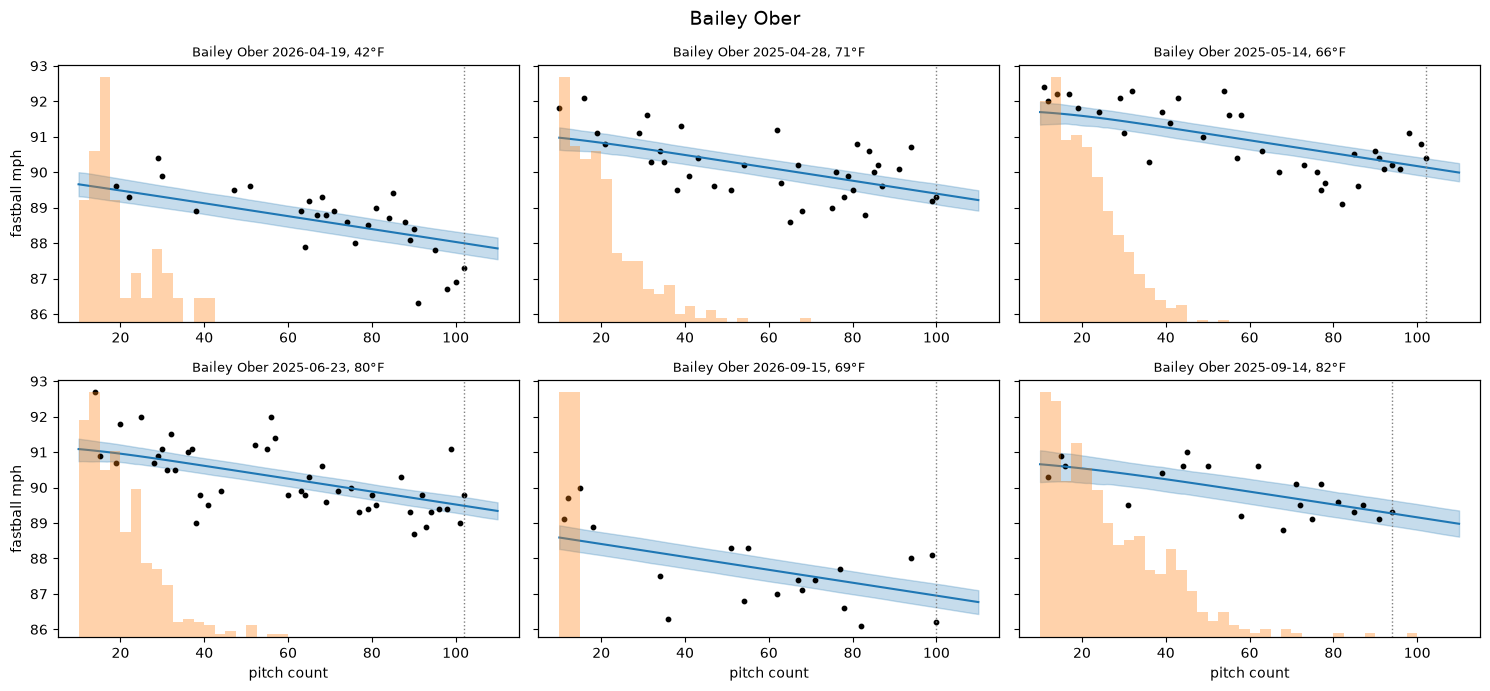

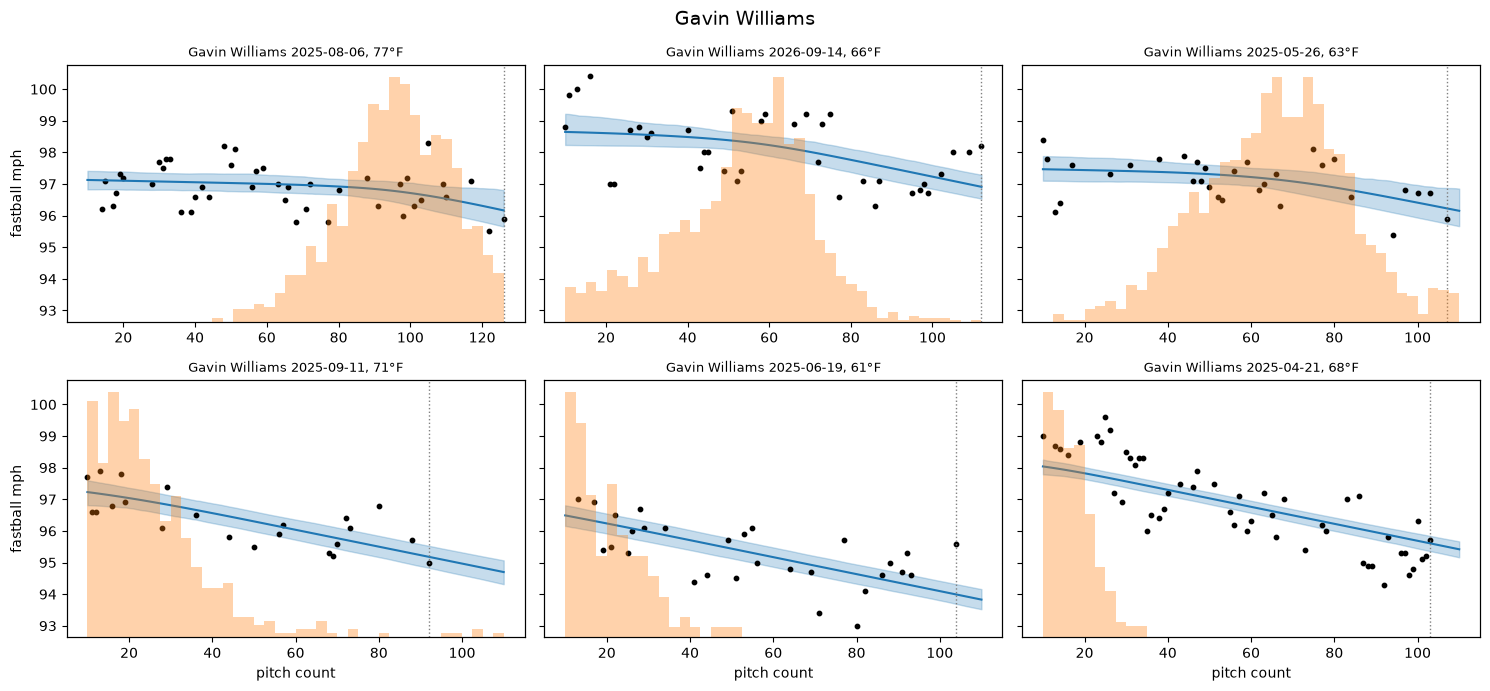

In [44]:
for nm, pid in PIDS.items():
    ids = S[S["pitcher"] == pid].sort_values("total_pitches", ascending=False).index[:6]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
    for ax, s_id in zip(axes.flat, ids):
        plot_start(ax, s_id)
    for ax in axes[-1]: ax.set_xlabel("pitch count")
    for ax in axes[:, 0]: ax.set_ylabel("fastball mph")
    fig.suptitle(nm, fontsize=14)
    plt.tight_layout(); plt.show()

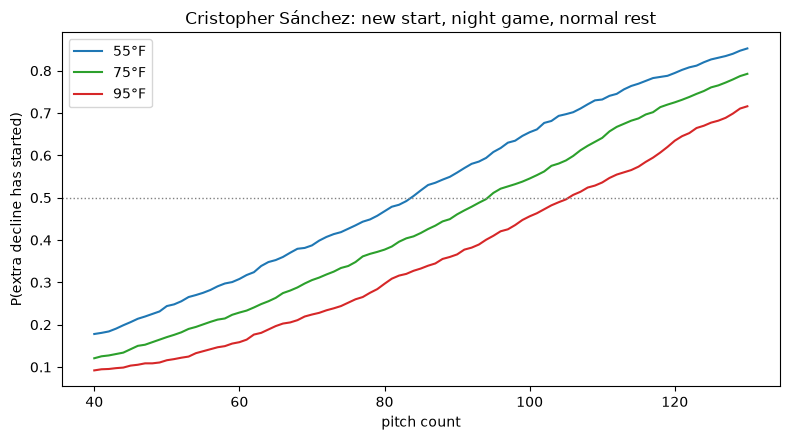

In [29]:
def p_fatigued(j, temp_f, rest=5, day=0, grid=np.arange(40, 131)):
    x = np.array([(temp_f - 70) / 10, np.clip(rest - 5, -1, 3), day], dtype=float)   # same order as COVS
    noise = np.random.default_rng(SEED).standard_normal(len(post["sigma"]))
    tau_new = post["tau_pitcher"][:, j] + post["beta"] @ x + post["sd_tau_start"] * noise
    return grid, (tau_new[:, None] < grid[None, :]).mean(0)

j = int(np.argmax(S.groupby("pitcher_id").size().to_numpy()))
fig, ax = plt.subplots(figsize=(8, 4.5))
for t, col in [(55, "tab:blue"), (75, "tab:green"), (95, "tab:red")]:
    g, p = p_fatigued(j, t)
    ax.plot(g, p, color=col, label=f"{t}°F")
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("pitch count"); ax.set_ylabel("P(extra decline has started)")
ax.set_title(f"{NAMES.get(int(PITCHERS[j]), PITCHERS[j])}: new start, night game, normal rest")
ax.legend(); plt.tight_layout(); plt.show()

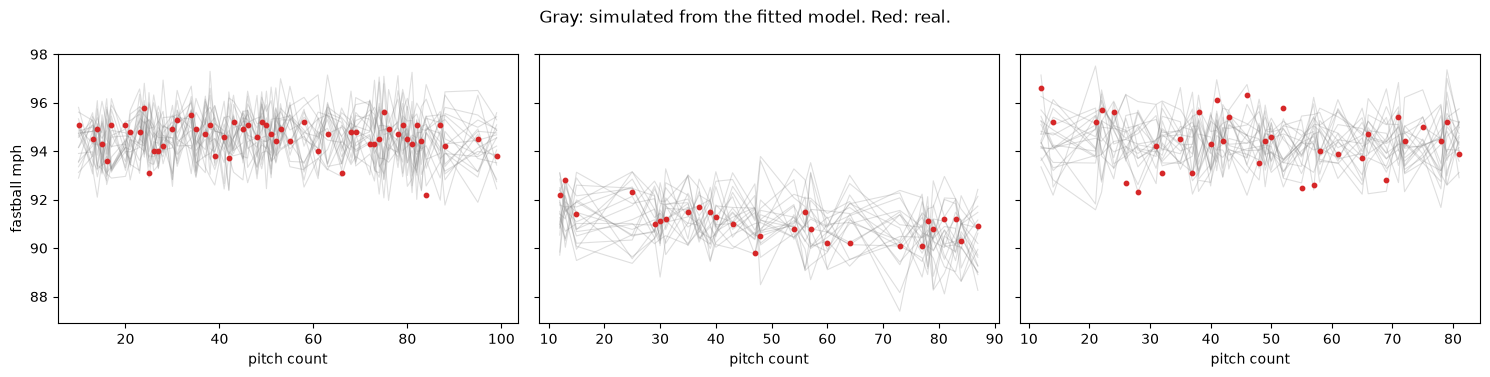

Residual SD: 0.89 mph | posterior sigma: 0.91 mph


In [14]:
DETS = {"tau_pitcher", "slope_pitcher", "drift_pitcher", "tau_start", "base_start"}
sub = {k: v[:200] for k, v in post.items() if k not in DETS}      # 200 draws is plenty for a visual check
ppc = Predictive(fatigue_model, posterior_samples=sub, return_sites=["v"])(
    jax.random.PRNGKey(SEED + 2), **DATA)["v"]
ppc = np.asarray(ppc)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, s_id in zip(axes, np.random.default_rng(3).choice(len(S), 3, replace=False)):
    m = DATA["start_idx"] == s_id
    for k in range(20):
        ax.plot(DATA["pc"][m], ppc[k][m], color="gray", alpha=0.25, lw=0.8)
    ax.scatter(DATA["pc"][m], V[m], color="tab:red", s=10, zorder=3)
    ax.set_xlabel("pitch count")
axes[0].set_ylabel("fastball mph")
plt.suptitle("Gray: simulated from the fitted model. Red: real."); plt.tight_layout(); plt.show()

resid = V - ppc.mean(0)
print(f"Residual SD: {resid.std():.2f} mph | posterior sigma: {post['sigma'].mean():.2f} mph")

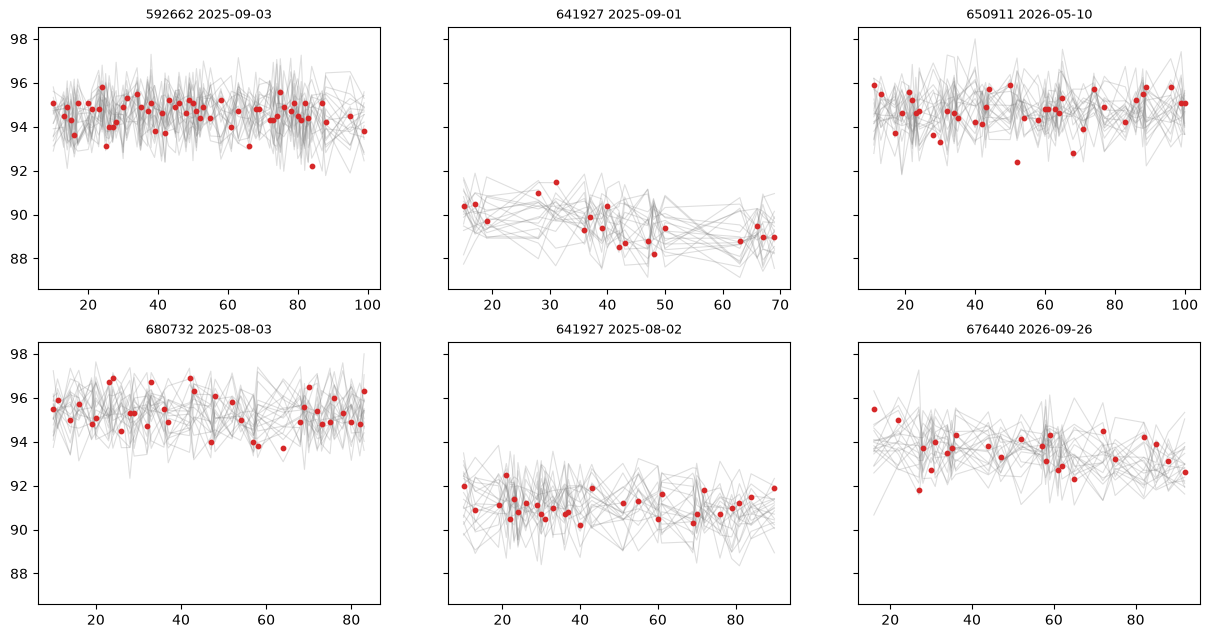

In [35]:
N_SHOW = 6
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for ax, s_id in zip(axes.flat, np.random.default_rng(3).choice(len(S), N_SHOW, replace=False)):
    m = DATA["start_idx"] == s_id
    for k in range(20):
        ax.plot(DATA["pc"][m], ppc[k][m], color="gray", alpha=0.25, lw=0.8)
    ax.scatter(DATA["pc"][m], V[m], color="tab:red", s=10, zorder=3)
    ax.set_title(f"{S.loc[s_id, 'name'] if 'name' in S else S.loc[s_id, 'pitcher']} "
                 f"{S.loc[s_id, 'game_date']:%Y-%m-%d}", fontsize=9)

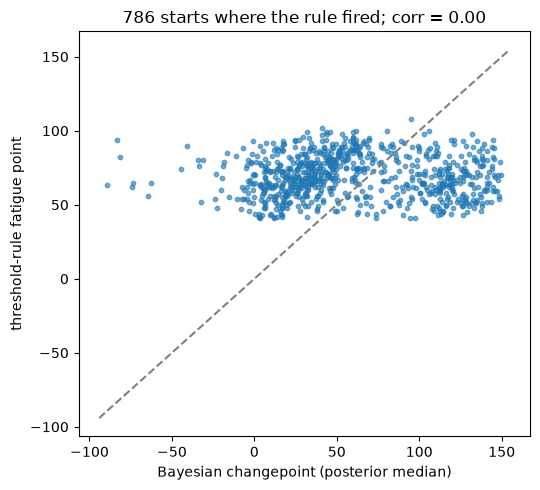

In [26]:
def rule_point(g, drop=1.0, window=8, base_hi=40):
    g = g.sort_values("pitch_count")
    base = g.loc[g["pitch_count"] <= base_hi, "release_speed"].median()
    roll = g["release_speed"].rolling(window).mean()
    hit = g[(g["pitch_count"] > base_hi) & (roll <= base - drop)]
    return hit["pitch_count"].iloc[0] if len(hit) else np.nan

rule = obs.groupby("start_id").apply(rule_point, include_groups=False)
cmp_ = pd.DataFrame({"rule": rule, "tau_median": np.median(post["tau_start"], axis=0)[rule.index]}).dropna()
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(cmp_["tau_median"], cmp_["rule"], s=10, alpha=0.6)
lim = [cmp_.min().min() - 5, cmp_.max().max() + 5]
ax.plot(lim, lim, ls="--", color="gray")
ax.set_xlabel("Bayesian changepoint (posterior median)"); ax.set_ylabel("threshold-rule fatigue point")
ax.set_title(f"{len(cmp_)} starts where the rule fired; corr = {cmp_.corr().iloc[0, 1]:.2f}")
plt.tight_layout(); plt.show()

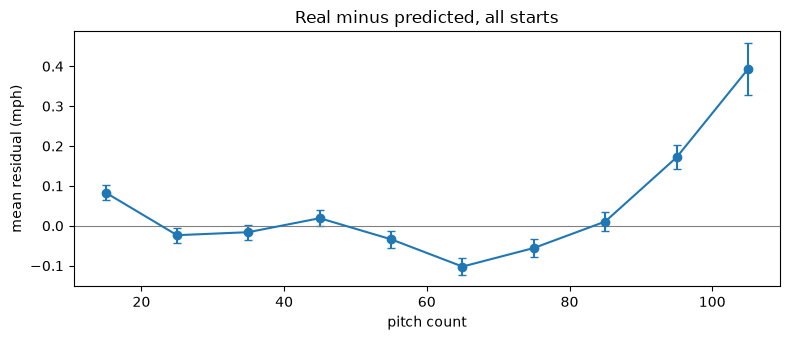

Share of real pitches inside the 90% predictive interval: 0.908


In [15]:
ppc_mean = ppc.mean(0)
resid = V - ppc_mean

# 1. Systematic misses by pitch count: should hover around 0 everywhere
r = pd.DataFrame({"pc_bin": (DATA["pc"] // 10) * 10 + 5, "resid": resid})
rb = r.groupby("pc_bin")["resid"].agg(["mean", "sem", "size"])
rb = rb[rb["size"] >= 50]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(rb.index, rb["mean"], yerr=1.96 * rb["sem"], fmt="o-", capsize=3)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("pitch count"); ax.set_ylabel("mean residual (mph)")
ax.set_title("Real minus predicted, all starts"); plt.tight_layout(); plt.show()

# 2. Coverage: about 90% of real pitches should fall inside the 90% predictive interval
lo, hi = np.percentile(ppc, [5, 95], axis=0)
print(f"Share of real pitches inside the 90% predictive interval: {((V >= lo) & (V <= hi)).mean():.3f}")

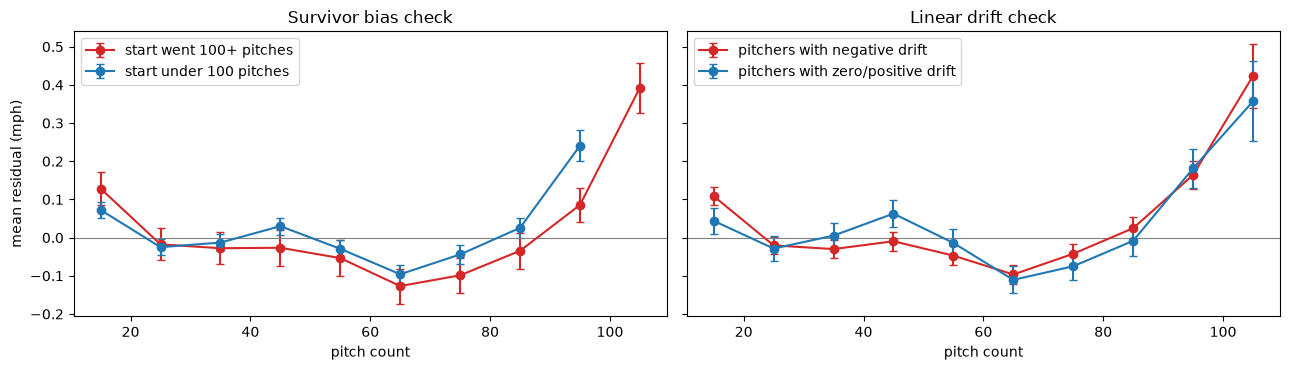

In [16]:
r = pd.DataFrame({
    "pc_bin": (DATA["pc"] // 10) * 10 + 5,
    "resid": resid,
    "deep_start": obs["start_id"].map(S["total_pitches"]).to_numpy() >= 100,
    "drift_neg": post["drift_pitcher"].mean(0)[DATA["pitcher_of_start"][DATA["start_idx"]]] < 0,
})

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col, labels, title in [
        (axes[0], "deep_start", {True: "start went 100+ pitches", False: "start under 100 pitches"},
         "Survivor bias check"),
        (axes[1], "drift_neg", {True: "pitchers with negative drift", False: "pitchers with zero/positive drift"},
         "Linear drift check")]:
    for key, color in [(True, "tab:red"), (False, "tab:blue")]:
        g = r[r[col] == key].groupby("pc_bin")["resid"].agg(["mean", "sem", "size"])
        g = g[g["size"] >= 50]
        ax.errorbar(g.index, g["mean"], yerr=1.96 * g["sem"], fmt="o-", capsize=3,
                    color=color, label=labels[key])
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel("pitch count"); ax.set_title(title); ax.legend()
axes[0].set_ylabel("mean residual (mph)")
plt.tight_layout(); plt.show()

In [ ]:
#The decline shape itself needs to flatten out

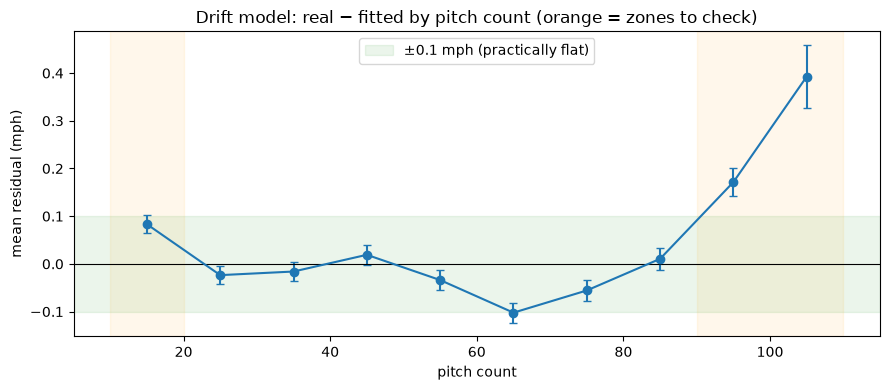

,mean,lo,hi,size,off zero?
pc_bin,,,,,
15.0,0.083,0.064,0.102,8037,yes
25.0,-0.024,-0.043,-0.005,8194,yes
35.0,-0.016,-0.035,0.003,7956,
45.0,0.019,-0.001,0.040,7226,
55.0,-0.034,-0.055,-0.013,7330,yes
65.0,-0.102,-0.123,-0.081,7392,yes
75.0,-0.056,-0.077,-0.034,6752,yes
85.0,0.011,-0.012,0.034,5815,
95.0,0.171,0.141,0.202,3258,yes


,mean resid (mph),95% lo,95% hi,pitches,flat?
pitches 10–20,0.078,0.060,0.096,8856.0,yes (< 0.1 mph)
pitches 21–89,-0.031,-0.038,-0.023,49846.0,yes (< 0.1 mph)
pitches 90+,0.210,0.182,0.237,3919.0,no


In [17]:
# Mean residual (real − fitted) by pitch count, for the drift model
rb = (pd.DataFrame({"pc_bin": (DATA["pc"] // 10) * 10 + 5, "resid": resid})
        .groupby("pc_bin")["resid"].agg(["mean", "sem", "size"]))
rb = rb[rb["size"] >= 50]
rb["lo"], rb["hi"] = rb["mean"] - 1.96 * rb["sem"], rb["mean"] + 1.96 * rb["sem"]
rb["off zero?"] = np.where((rb["lo"] > 0) | (rb["hi"] < 0), "yes", "")   # 95% interval excludes 0

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(rb.index, rb["mean"], yerr=1.96 * rb["sem"], fmt="o-", capsize=3, color="tab:blue")
ax.axhspan(-0.1, 0.1, color="green", alpha=0.08, label="±0.1 mph (practically flat)")
ax.axhline(0, color="black", lw=0.8)
for lo, hi in [(10, 20), (90, rb.index.max() + 5)]:
    ax.axvspan(lo, hi, color="orange", alpha=0.08)
ax.set_xlabel("pitch count"); ax.set_ylabel("mean residual (mph)")
ax.set_title("Drift model: real − fitted by pitch count (orange = zones to check)")
ax.legend(); plt.tight_layout(); plt.show()

display(rb[["mean", "lo", "hi", "size", "off zero?"]].round(3))

def zone(lo, hi):
    z = resid[(DATA["pc"] >= lo) & (DATA["pc"] <= hi)]
    return pd.Series({"mean resid (mph)": z.mean(), "95% lo": z.mean() - 1.96 * z.std() / np.sqrt(len(z)),
                      "95% hi": z.mean() + 1.96 * z.std() / np.sqrt(len(z)), "pitches": len(z)})

zones = pd.DataFrame({"pitches 10–20": zone(10, 20), "pitches 21–89": zone(21, 89),
                      "pitches 90+": zone(90, 999)}).T
zones["flat?"] = np.where(zones["mean resid (mph)"].abs() < 0.1, "yes (< 0.1 mph)", "no")
display(zones.round(3))

/Users/jinzhixu/spark-env/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(
/Users/jinzhixu/spark-env/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.69 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


Computed from 1500 posterior samples and 62621 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -84442.96   205.61
p_loo     2848.71        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.69]   (good)     62556   99.9%
   (0.69, 1]   (bad)         57    0.1%
   (1, Inf)   (very bad)     8    0.0%


elpd_loo per pitch: -1.348
p_loo (effective parameters): 2849  vs. raw parameter count: 4,188.0
Pareto k > 0.7 (LOO unreliable for that pitch): 57 of 62,621 pitches


,mean_elpd,max_k,n_high_k
pc_bin,,,
15.0,-1.345,1.117,4
25.0,-1.333,1.040,6
35.0,-1.309,0.403,0
45.0,-1.335,0.473,0
55.0,-1.351,0.492,0
65.0,-1.376,0.718,1
75.0,-1.358,1.324,11
85.0,-1.372,1.282,11
95.0,-1.379,1.324,22


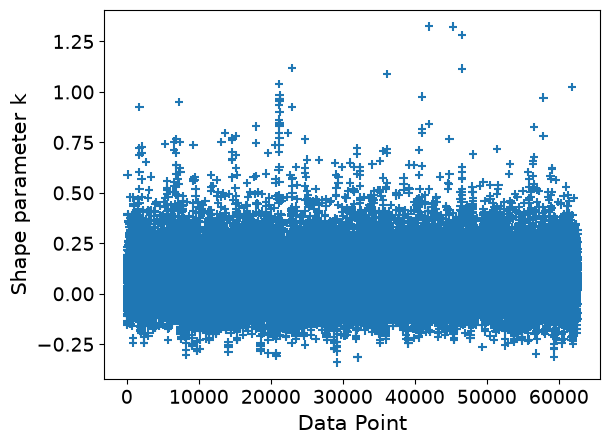

In [18]:
import arviz as az

idata = az.from_numpyro(mcmc)                 # mcmc = the drift model fit
loo = az.loo(idata, pointwise=True)
print(loo)

n_params = sum(np.prod(v.shape[1:]) for k, v in post.items()
               if k not in {"tau_pitcher", "slope_pitcher", "drift_pitcher", "tau_start", "base_start"})
print(f"\nelpd_loo per pitch: {loo.elpd_loo / len(V):.3f}")
print(f"p_loo (effective parameters): {loo.p_loo:.0f}  vs. raw parameter count: {n_params:,}")

k = np.asarray(loo.pareto_k)
print(f"Pareto k > 0.7 (LOO unreliable for that pitch): {(k > 0.7).sum()} of {len(k):,} pitches")

# Where are the hard-to-predict pitches? Pareto k and pointwise elpd by pitch count
pt = pd.DataFrame({"pc_bin": (DATA["pc"] // 10) * 10 + 5, "elpd_i": np.asarray(loo.loo_i), "k": k})
display(pt.groupby("pc_bin").agg(mean_elpd=("elpd_i", "mean"), max_k=("k", "max"),
                                 n_high_k=("k", lambda x: (x > 0.7).sum())).round(3))
az.plot_khat(loo); plt.show()

In [21]:
bad = pd.DataFrame({"pitch_count": DATA["pc"], "velo": V, "fitted": V - resid, "k": k,
                    "start_id": DATA["start_idx"]})
bad = bad[bad["k"] > 0.7].merge(S[["start_id", "pitcher", "game_date", "total_pitches"]], on="start_id")
bad["name"] = bad["pitcher"].map(lambda p: NAMES.get(int(p), p))
display(bad.sort_values("k", ascending=False).round(2))
print(bad["start_id"].value_counts().head())     # are a few starts responsible for most of them?

,pitch_count,velo,fitted,k,start_id,pitcher,game_date,total_pitches,name
46,79.0,91.300003,94.290001,1.32,1034,666200,2026-07-18,90,Jesús Luzardo
49,90.0,90.699997,92.739998,1.32,415,642547,2026-04-12,100,Freddy Peralta
50,88.0,94.800003,96.589996,1.28,1537,671737,2026-06-03,104,Taj Bradley
36,16.0,92.599998,93.419998,1.12,1618,680732,2025-05-23,89,Sean Burke
51,89.0,95.800003,96.639999,1.12,1537,671737,2026-06-03,104,Taj Bradley
41,104.0,97.199997,95.239998,1.09,1040,666200,2026-08-26,104,Jesús Luzardo
19,20.0,91.300003,91.599998,1.04,558,656427,2025-06-02,99,Jack Flaherty
56,94.0,92.199997,92.709999,1.02,434,642547,2026-08-10,98,Freddy Peralta
33,96.0,93.099998,92.110001,0.99,558,656427,2025-06-02,99,Jack Flaherty
43,78.0,95.300003,93.190002,0.98,631,656605,2026-04-19,89,Mitch Keller


start_id
558     15
1622     3
631      3
410      2
1618     2
Name: count, dtype: int64


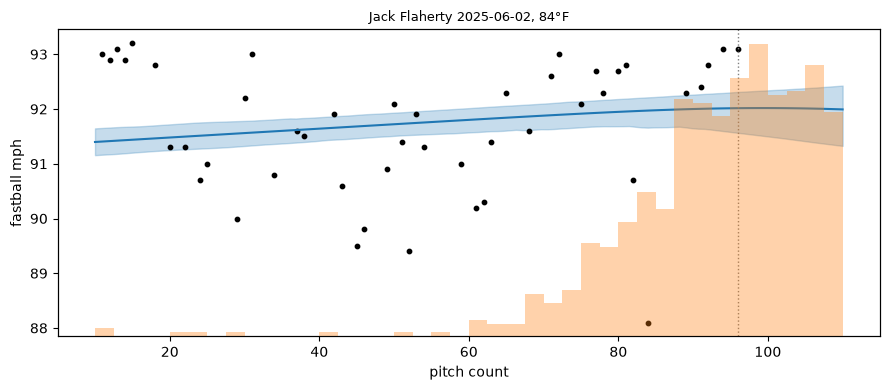

Jack Flaherty | fastball type that day: ['FF'] | pitches: 46 | total pitches: 99


,size,mean,min,max
pitch_type,,,,
CH,2,86.8,85.9,87.7
FF,49,91.7,88.1,93.2
KC,23,76.7,73.3,78.4
SI,1,88.5,88.5,88.5
SL,24,83.6,81.2,85.5


In [24]:
def plot_start(ax, s_id, n_draws=400):
    m = DATA["start_idx"] == s_id
    pc_s, v_s = DATA["pc"][m], V[m]
    j = DATA["pitcher_of_start"][s_id]
    grid = np.linspace(BASE_LO, max(pc_s.max(), 110), 120)
    idx = np.random.default_rng(SEED).choice(len(post["sigma"]), n_draws, replace=False)
    tau = post["tau_start"][idx, s_id][:, None]
    curves = (post["base_start"][idx, s_id][:, None]
              + post["drift_pitcher"][idx, j][:, None] * (grid[None, :] - PC_CENTER)
              - post["slope_pitcher"][idx, j][:, None] * (SMOOTH * np.logaddexp(0, (grid[None, :] - tau) / SMOOTH)))
    ax.fill_between(grid, *np.percentile(curves, [5, 95], axis=0), alpha=0.25, color="tab:blue")
    ax.plot(grid, curves.mean(0), color="tab:blue")
    ax.scatter(pc_s, v_s, s=10, color="black")
    ax2 = ax.twinx()
    ax2.hist(post["tau_start"][:, s_id], bins=40, range=(grid[0], grid[-1]), color="tab:orange", alpha=0.35)
    ax2.set_yticks([])
    ax.axvline(pc_s.max(), color="gray", ls=":", lw=1)
    r = S.loc[s_id]
    ax.set_title(f"{NAMES.get(int(r['pitcher']), r['pitcher'])} {r['game_date']:%Y-%m-%d}, {r['temp_f']:.0f}°F",
                 fontsize=9)

fig, ax = plt.subplots(figsize=(9, 4))
plot_start(ax, 558)
ax.set_xlabel("pitch count"); ax.set_ylabel("fastball mph")
plt.tight_layout(); plt.show()

g558 = obs[obs["start_id"] == 558][["pitch_count", "pitch_type", "release_speed"]]
print(NAMES.get(656427, 656427), "| fastball type that day:", g558["pitch_type"].unique(),
      "| pitches:", len(g558), "| total pitches:", S.loc[558, "total_pitches"])
display(st[(st["game_pk"] == S.loc[558, "game_pk"]) & (st["pitcher"] == S.loc[558, "pitcher"])]
          .groupby("pitch_type")["release_speed"].agg(["size", "mean", "min", "max"]).round(1))